In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import os
import pandas as pd
import datetime as dt
import matplotlib.colors as mcolors
import json
import csv
from itertools import product
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap, Normalize
import seaborn as sns
import pandas as pd



In [2]:
class data():
    def __init__(self,folder,period,start_date, end_date,BG,BG_ds,footprint='spec001_mr',correlation='with',g_err=2,i_err=3):
        self.folder = folder
        self.period = period
        self.start_date=start_date
        self.end_date=end_date
        self.correlation=correlation
        self.color=''
        self.BG=BG
        self.BG_ds=BG_ds
        self.g_err=g_err
        self.i_err=i_err
        self.footprint=footprint
        self.path = f'{self.folder}/2x2/{self.correlation}_correlation/footprint_{self.footprint}/{self.g_err}ppm_gosat_meas_err/{self.i_err}ppm_insitu_meas_err/'
        
    # Class attributes
    def read_fluxes(self):
        self.fluxes=xr.open_dataset(f'{self.path}/{self.period}_{self.BG_ds}_bg.nc')
        self.fluxes['time']=pd.to_datetime(self.fluxes.time)
        self.fluxes=self.fluxes.where((self.fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(self.fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)
    def read_gosat(self):
        self.gosat=xr.open_dataset(f'{self.path}/gosat_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.gosat=self.gosat.drop_dims(['time','latitude','longitude'])
        self.gosat=self.gosat.where((self.gosat.release_time>=pd.to_datetime(self.start_date))&(self.gosat.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.gosat=self.gosat.where((self.gosat.release_lat>analy_region_lat[0])&(self.gosat.release_lat<analy_region_lat[1])&(self.gosat.release_lon>analy_region_lon[0])&(self.gosat.release_lon<analy_region_lon[1]),drop=True)

    def read_insitu(self):
        self.insitu=xr.open_dataset(f'{self.path}/insitu_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.insitu=self.insitu.drop_dims(['time','latitude','longitude'])
        self.insitu=self.insitu.where((self.insitu.release_time>=pd.to_datetime(self.start_date))&(self.insitu.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.insitu=self.insitu.where((self.insitu.release_lat>analy_region_lat[0])&(self.insitu.release_lat<analy_region_lat[1])&(self.insitu.release_lon>analy_region_lon[0])&(self.insitu.release_lon<analy_region_lon[1]),drop=True)
    def read_tccon(self):
        self.tccon=xr.open_dataset(f'{self.path}/TCCON_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.tccon=self.tccon.drop_dims(['time','latitude','longitude'])
        self.tccon=self.tccon.where((self.tccon.release_time>=pd.to_datetime(self.start_date))&(self.tccon.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.tccon=self.tccon.where((self.tccon.release_lat>analy_region_lat[0])&(self.tccon.release_lat<analy_region_lat[1])&(self.tccon.release_lon>analy_region_lon[0])&(self.tccon.release_lon<analy_region_lon[1]),drop=True)

    def read_data(self):
        self.read_fluxes()
        self.read_gosat()
        self.read_insitu()
        self.read_tccon()

In [3]:
def plot_inner_2x2_region_fluxes(datasets_dir,labels,parameters,parameters_uncertainty, colors,markers, title, start_date, end_date,spath):
    ''' plot time series of prior, posterior and TM5-4DVar reference fluxes for all grid cells in inner domain
    Args:
        data_dir:   path to inversion directory
        ref_flux_dir: TM5-4DVar flux directory
        gosat_err_val: gosat measurement error value
        meas_err_val: insitu measurement error value
        corr_str: sting indicating if with or withour correlation
        color_sel: color for posterior flux
        bg_str: TM5-4DVar dataset used for the background, defaults to RemoTeC_2.4.0+IS
    Returns: nothing, saves plot'''
    data={}
    for k,dir in enumerate(datasets_dir):
        print(dir)
        data[labels[k]]=xr.open_dataset(dir).sel(latitude=slice(20,48), longitude=slice(-123,-73))

    title_str=f'Total 2x2 flux, {title}'
    lat_lon_list=[(lat, lon) for lat in data[labels[0]].latitude.values for lon in data[labels[0]].longitude.values]
    # sort by latitude descending, longitude ascending
    lat_lon_list=sorted(lat_lon_list, key=lambda x: (-x[0], x[1]))
    # plot overview
    fig, ax=plt.subplots(data[labels[0]].latitude.size, data[labels[0]].longitude.size, figsize=(data[labels[0]].longitude.size*6, data[labels[0]].latitude.size*6), sharey=True)
    ax=ax.flatten()
    # marker size
    ms=2
    for i in range(0, len(lat_lon_list)):
        lat_sel, lon_sel =lat_lon_list[i]
        # select region
        for k in range(len(labels)):
            if 'GCP' in labels[k]:
                s=labels[k][-1]
                data_sel=data[labels[k]].sel(ensemble_member=int(s))
                data_sel=data_sel.sel(latitude=lat_sel, longitude=lon_sel)
                name=''
                for r in data_sel.ensemble_member_name.values[0]:
                    name+=r
                ax[i].plot(data_sel.time, data_sel[parameters[k]], c=colors[k], marker=markers[k], markersize=ms, label=name)
            else:
                data_sel=data[labels[k]].sel(latitude=lat_sel, longitude=lon_sel)
                ax[i].plot(data_sel.time, data_sel[parameters[k]], c=colors[k], marker=markers[k], markersize=ms, label=labels[k])
            if parameters_uncertainty[k]!=False:
                ax[i].fill_between(data_sel.time, data_sel[parameters[k]]-data_sel[parameters_uncertainty[k]], data_sel[parameters[k]]+data_sel[parameters_uncertainty[k]], 
                                color=colors[k], alpha=0.2)        
        ax[i].legend()
        ax[i].set_title(f'lat/lon: {lat_sel}/{lon_sel}')
        ax[i].set_xlim(start_date,end_date)
        #ax[i].set_xlim(dt.date(2010,1,1), dt.date(2010,12,31))
        ax[i].tick_params(labelleft=True)
        ax[i].set_ylim(-4e-7, 4e-7)
        # You can change the step of range() as you prefer (now, it selects each third month) 
        ax[i].xaxis.set_major_locator(mdates.MonthLocator(bymonth=range(1,12,3)))
        ax[i].xaxis.set_minor_locator(mdates.MonthLocator(bymonth=range(1,13,1)))
        ax[i].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        ax[i].grid(which='both', c='grey', alpha=0.5)
    fig.suptitle(title_str)
    fig.tight_layout(rect=[0, 0., 1, 0.98])

    fig.savefig(spath)
    print(f'saved to: {spath}')
    plt.close()
    return

In [4]:
def plot_map(data,label,ax,vmin=-0.6,vmax=0.6):
    plot=data.plot(ax=ax, cmap='RdBu_r', vmin=vmin, vmax=vmax, cbar_kwargs={'location':'bottom','shrink':0.85, 'label':label})
    plot.colorbar.ax.xaxis.label.set_size(12)
    plot.colorbar.ax.tick_params(labelsize=12)
        
    ax.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='g')
    ax.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='g')
    ax.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='g')
    ax.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='g')
    
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10}
    gl.ylabel_style = {'size': 10}
    ax.grid(c='lightgrey')
    ax.set_xlim(-134,-62) 
    ax.set_ylim(12,56)
    ax.tick_params(labelsize=20)
    ax.set_title('')

In [5]:
def plot_map_analysisregion(data,label,ax,vmin=-0.6,vmax=0.6):
    plot=data.plot(ax=ax, cmap='RdBu_r', vmin=vmin, vmax=vmax, rasterized=True,cbar_kwargs={'location':'bottom','shrink':0.85, 'label':label})
    plot.colorbar.ax.xaxis.label.set_size(18)
    plot.colorbar.ax.tick_params(labelsize=16)
        
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 14}
    gl.ylabel_style = {'size': 14}
    ax.grid(c='lightgrey')
    ax.set_xlim(analy_region_lon[0],analy_region_lon[1]) 
    ax.set_ylim(analy_region_lat[0],analy_region_lat[1])
    ax.tick_params(labelsize=20)
    ax.set_title('')

In [6]:
def plot_map_divided(data,label,ax,vmin=-0.6,vmax=0.6):
    plot=data.plot(ax=ax, cmap='RdBu_r', vmin=vmin, vmax=vmax, cbar_kwargs={'location':'bottom','shrink':0.85, 'label':label})
    plot.colorbar.ax.xaxis.label.set_size(12)
    plot.colorbar.ax.tick_params(labelsize=12)
    for i in range(n_regions[0]): #lat
        for j in range(n_regions[1]): #lon
            ax.hlines(regions_lat[i],regions_lon[j], regions_lon[j+1],color='b')
            ax.vlines(regions_lon[j],regions_lat[i],regions_lat[i+1],color='b')
        
    ax.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='g')
    ax.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='g')
    ax.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='g')
    ax.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='g')
    
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10}
    gl.ylabel_style = {'size': 10}
    ax.grid(c='lightgrey')
    ax.set_xlim(-134,-62) 
    ax.set_ylim(12,56)
    ax.tick_params(labelsize=20)
    ax.set_title('')

In [7]:
def get_start_date_of_week(date):
    ''' Get monday date of the of the week containing the given date
    Args: date
    Returns: date of monday in corresponding week'''
    start_date=date-dt.timedelta(days=date.weekday())   # dt.date().weekday() goes from 0 to 6
    return start_date

In [8]:
analy_region_lat=[20,48]
analy_region_lon=[-126,-70]

# four_times_four 
res=2
n_regions=[2,3] #lat, lon
lat_dist=round((analy_region_lat[1]-analy_region_lat[0])/n_regions[0]/res)*res
lon_dist=round((analy_region_lon[1]-analy_region_lon[0])/n_regions[1]/res)*res
#define region edges
regions_lat=[]
for i in range(n_regions[0]+1): #lat
    if i == n_regions[0]:
        regions_lat.append(analy_region_lat[1])
    else:
        regions_lat.append(analy_region_lat[0]+i*lat_dist)
regions_lon=[]
for i in range(n_regions[1]+1): #lat
    if i == n_regions[1]:
        regions_lon.append(analy_region_lon[1])
    else:
        regions_lon.append(analy_region_lon[0]+i*lon_dist)

In [9]:
print(regions_lat)
print(regions_lon)

[20, 34, 48]
[-126, -108, -90, -70]


In [10]:
period='20191001-20230331'
analysis_start_date, analysis_end_date =dt.date(2020,1,1), dt.date(2022,12,31)  
start_date, end_date =dt.date(2019,10,1), dt.date(2023,3,31)  
color=['red','blue','yellow','purple','gray','orange', 'pink']
savefig='figures_2/3years/model_anaylsis/3x2'

In [11]:
seasons={
    'winter': [12,1,2],
    'spring': [3,4,5],
    'summer': [6,7,8],
    'autumn': [9.,10,11]
}

In [12]:
path='inversions_new/TM5_3_years/'
BG='TM5'
BG_ds='RemoTeC_2.4.1+IS-land_ocean_bc'

inversion=data(path,period,start_date, end_date,BG,BG_ds,footprint='spec001_mr',correlation='with',g_err=2,i_err=3)
inversion.read_data()

In [13]:
TM54DVar_posterior_flux=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc')
TM54DVar_posterior_flux=TM54DVar_posterior_flux.where((TM54DVar_posterior_flux.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(TM54DVar_posterior_flux.time<=pd.to_datetime(analysis_end_date)),drop=True)

In [14]:
prior=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_prior_cut_weekly.nc')
prior=prior.where((prior.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(prior.time<=pd.to_datetime(analysis_end_date)),drop=True)

In [15]:
GCP=xr.open_dataset('/work/bb1170/RUN/b383736/data/GCP/GCP2024_inversions_2x2_version1_2_20241021_cut_weekly.nc')
GCP=GCP.where((GCP.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(GCP.time<=pd.to_datetime(analysis_end_date)),drop=True)
gcp_names=[]
for i in GCP.ensemble_member:
    gcp_names.append(GCP.sel(ensemble_member=i).ensemble_member_name.values[0].sum())
print(gcp_names)


['CarboScope', 'CAMS', 'CTE', 'NISMON-CO2', 'CT-NOAA', 'CMS-Flux', 'CAMS-Satellite', 'GONGGA', 'COLA', 'GCASv2', 'UoE', 'IAPCAS', 'MIROC', 'NTFVAR']


# Evaluation of inversion

## CO2 fluxes

In [16]:
def plot_map(data,label,ax,vmin=-0.6,vmax=0.6):
    plot=data.plot(ax=ax, cmap='RdBu_r', vmin=vmin, vmax=vmax, cbar_kwargs={'location':'bottom', 'label':label})
    plot.colorbar.ax.xaxis.label.set_size(15)
    plot.colorbar.ax.tick_params(labelsize=15)

        
    ax.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='black')
    ax.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='black')
    ax.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='black')
    ax.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='black')
    
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 12}
    gl.ylabel_style = {'size': 12}
    ax.grid(c='lightgrey')
    ax.set_xlim(-134,-62) 
    ax.set_ylim(12,56)
    ax.tick_params(labelsize=20)
    ax.set_title('')

In [51]:
fig,axs=plt.subplots(1,1,figsize=(7,5.5), subplot_kw={'projection': ccrs.PlateCarree()})
fig.suptitle("Posterior", fontsize=20, fontweight='bold')
fig.subplots_adjust(right=0.85)
temp_inv=inversion.fluxes.where((inversion.fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(inversion.fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)
temp_inv=(temp_inv.TM5_posterior_flux).mean('time')*1e6
#plot_map(temp_inv,r'total CO2 flux [$\mathrm{\frac{mgCO2}{s m^2}}$]',axs,vmin=-0.15,vmax=0.15)
plot_map_analysisregion(temp_inv,r'Total CO$_2$ Flux [$\mathrm{\frac{mgCO2}{s m^2}}$]',axs,vmin=-0.15,vmax=0.15)
axs.set_aspect('equal')
plt.tight_layout()
plt.savefig(f'{savefig}/posterior/mean_map_posterior.pdf', bbox_inches='tight')
plt.close()

In [60]:
temp_inv=inversion.fluxes.where((inversion.fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(inversion.fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)
for season in seasons:
    print(season)
    temp=temp_inv.where((temp_inv.time.dt.month == seasons[season][0])|(temp_inv.time.dt.month == seasons[season][0])|(temp_inv.time.dt.month == seasons[season][0]),drop=True)
    temp=temp.TM5_posterior_flux.mean('time')*1e6
    fig,axs=plt.subplots(1,1,figsize=(7,5.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle("Posterior", fontsize=20, fontweight='bold')
    fig.text(0.5, 0.89, f"mean {season}", ha='center', fontsize=16, style='italic')
    fig.subplots_adjust(right=0.85, top=1.1)
    plot_map_analysisregion(temp,r'Total CO$_2$ Flux [$\mathrm{\frac{mgCO2}{s m^2}}$]',axs,vmin=-0.25,vmax=0.25)
    axs.set_aspect('equal')
    plt.tight_layout()
    plt.savefig(f'{savefig}/posterior/posterior_flux_{season}.pdf', bbox_inches='tight')
    plt.close()
    



winter
spring
summer
autumn


In [63]:
fig,axs=plt.subplots(1,1,figsize=(7,5.5), subplot_kw={'projection': ccrs.PlateCarree()})
fig.suptitle("Prior", fontsize=20, fontweight='bold')
fig.subplots_adjust(right=0.85)
temp_inv=inversion.fluxes.where((inversion.fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(inversion.fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)
temp_inv=(temp_inv.TM5_prior_flux).mean('time')*1e6
plot_map_analysisregion(temp_inv,r'Total CO$_2$ Flux [$\mathrm{\frac{mgCO2}{s m^2}}$]',axs,vmin=-0.15,vmax=0.15)
axs.set_aspect('equal')
plt.tight_layout()
plt.savefig(f'{savefig}/prior/mean_map_prior.pdf', bbox_inches='tight')
plt.close()

In [65]:
temp_inv=inversion.fluxes.where((inversion.fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(inversion.fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)
for season in seasons:
    print(season)
    temp=temp_inv.where((temp_inv.time.dt.month == seasons[season][0])|(temp_inv.time.dt.month == seasons[season][0])|(temp_inv.time.dt.month == seasons[season][0]),drop=True)
    temp=temp.TM5_prior_flux.mean('time')*1e6
    fig,axs=plt.subplots(1,1,figsize=(7,5.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle("Prior", fontsize=20, fontweight='bold')
    fig.text(0.5, 0.89, f"mean {season}", ha='center', fontsize=16, style='italic')
    fig.subplots_adjust(right=0.85,top=1.1)
    plot_map_analysisregion(temp,r'Total CO$_2$ Flux [$\mathrm{\frac{mgCO2}{s m^2}}$]',axs,vmin=-0.25,vmax=0.25)
    axs.set_aspect('equal')
    plt.tight_layout()
    plt.savefig(f'{savefig}/prior/prior_flux_{season}.pdf',bbox_inches='tight')
    plt.close()




winter
spring
summer
autumn


In [67]:
fig,axs=plt.subplots(1,1,figsize=(7,5.5), subplot_kw={'projection': ccrs.PlateCarree()})
fig.suptitle("Posterior - Prior", fontsize=20, fontweight='bold')
fig.subplots_adjust(right=0.85)
temp_inv=inversion.fluxes.where((inversion.fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(inversion.fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)
temp_inv=(temp_inv.TM5_posterior_flux -temp_inv.TM5_prior_flux).mean('time')*1e6
plot_map_analysisregion(temp_inv,r'Total CO$_2$ Flux [$\mathrm{\frac{mgCO2}{s m^2}}$]',axs,vmin=-0.15,vmax=0.15)
axs.set_aspect('equal')
plt.tight_layout()
plt.savefig(f'{savefig}/posterior-prior/mean_map_pos-prior.pdf', bbox_inches='tight')
plt.close()

In [72]:
temp_inv=inversion.fluxes.where((inversion.fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(inversion.fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)
for season in seasons:
    print(season)
    temp=temp_inv.where((temp_inv.time.dt.month == seasons[season][0])|(temp_inv.time.dt.month == seasons[season][0])|(temp_inv.time.dt.month == seasons[season][0]),drop=True)
    temp=(temp.TM5_posterior_flux- temp.TM5_prior_flux).mean('time')*1e6
    fig,axs=plt.subplots(1,1,figsize=(7,5.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle("Posterior - Prior", fontsize=20 , fontweight='bold')
    fig.text(0.5, 0.89, f"mean {season}", ha='center', fontsize=16, style='italic')
    fig.subplots_adjust(right=0.85,top=1.1)
    plot_map_analysisregion(temp,r'Total CO$_2$ Flux [$\mathrm{\frac{mgCO2}{s m^2}}$]',axs,vmin=-0.25,vmax=0.25)
    axs.set_aspect('equal')
    plt.tight_layout()
    plt.savefig(f'{savefig}/posterior-prior/posterior-prior_flux_{season}.pdf', bbox_inches='tight')
    plt.close()



winter
spring
summer
autumn


In [71]:
fig,axs=plt.subplots(1,1,figsize=(7,5.5), subplot_kw={'projection': ccrs.PlateCarree()})
fig.suptitle("(Posterior-Prior)/|Prior|", fontsize=20, fontweight='bold')
fig.subplots_adjust(right=0.85)
temp_inv=inversion.fluxes.where((inversion.fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(inversion.fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)
temp_inv=((temp_inv.TM5_posterior_flux-temp_inv.TM5_prior_flux)/np.abs(temp_inv.TM5_prior_flux)).mean('time')
plot_map_analysisregion(temp_inv,r'    ',axs,vmin=-3,vmax=3)
axs.set_aspect('equal')
plt.tight_layout()
plt.savefig(f'{savefig}/posterior/mean_map_Prior-posterior_div_prior.pdf', bbox_inches='tight')
plt.close()

In [ ]:
temp_inv=inversion.fluxes.where((inversion.fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(inversion.fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)
for season in seasons:
    print(season)
    temp=temp_inv.where((temp_inv.time.dt.month == seasons[season][0])|(temp_inv.time.dt.month == seasons[season][0])|(temp_inv.time.dt.month == seasons[season][0]),drop=True)
    temp=((temp.TM5_posterior_flux-temp.TM5_prior_flux)/np.abs(temp.TM5_prior_flux)).mean('time')
    fig,axs=plt.subplots(1,1,figsize=(7,5.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle("(Posterior-Prior)/|Prior|", fontsize=20, fontweight='bold')
    fig.text(0.5, 0.89, f"mean {season}", ha='center', fontsize=16, style='italic')
    fig.subplots_adjust(right=0.85, top=1.1)
    plot_map_analysisregion(temp,r'',axs,vmin=-4,vmax=4)
    axs.set_aspect('equal')
    plt.tight_layout()
    plt.savefig(f'{savefig}/posterior/posterior-prior_div_prior_flux_{season}.pdf', bbox_inches='tight')
    plt.close()




winter
spring
summer
autumn


## Plot Averaging Kernel

In [17]:
def plot_averaging_kernel(data,label,ax):
    cmap = LinearSegmentedColormap.from_list( 'white_red',[(0.00, 'white'), (1e-6, plt.cm.Reds(0.05)), (0.01, plt.cm.Reds(0.10)), (0.1, plt.cm.Reds(0.50)),(1.00, plt.cm.Reds(1.00)) ])

    #plot=data.plot(ax=ax, cmap= 'RdBu_r', norm=norm, cbar_kwargs={'location':'bottom', 'label':label})
    plot=data.plot(ax=ax, cmap= cmap, vmin=0, vmax=0.4, cbar_kwargs={'location':'bottom', 'label':label})
    plot.colorbar.ax.xaxis.label.set_size(15)
    plot.colorbar.ax.tick_params(labelsize=15)
        
    ax.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='g')
    ax.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='g')
    ax.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='g')
    ax.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='g')
    
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 12}
    gl.ylabel_style = {'size': 12}
    ax.grid(c='lightgrey')
    ax.set_xlim(-134,-62) 
    ax.set_ylim(12,56)
    ax.tick_params(labelsize=20)
    ax.set_title('')

In [18]:
def plot_averaging_kernel_analysisregion(data,label,ax):
    cmap = LinearSegmentedColormap.from_list( 'white_red',[(0.00, 'white'), (1e-6, plt.cm.Reds(0.05)), (0.01, plt.cm.Reds(0.10)), (0.1, plt.cm.Reds(0.50)),(1.00, plt.cm.Reds(1.00)) ])

    #plot=data.plot(ax=ax, cmap= 'RdBu_r', norm=norm, cbar_kwargs={'location':'bottom', 'label':label})
    plot=data.plot(ax=ax, cmap= cmap, vmin=0, vmax=0.4,rasterized=True, cbar_kwargs={'location':'bottom', 'label':label})
    plot.colorbar.ax.xaxis.label.set_size(16)
    plot.colorbar.ax.tick_params(labelsize=16)
        
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 14}
    gl.ylabel_style = {'size': 14}
    ax.grid(c='lightgrey')
    ax.set_xlim(analy_region_lon[0],analy_region_lon[1]) 
    ax.set_ylim(analy_region_lat[0],analy_region_lat[1])
    ax.tick_params(labelsize=20)
    ax.set_title('')

In [19]:
fig,axs=plt.subplots(1,1,figsize=(7,5.5), subplot_kw={'projection': ccrs.PlateCarree()})
fig.suptitle("Diagonal of Averaging Kernel", fontsize=20, fontweight='bold')
fig.subplots_adjust(right=0.85)
temp_inv=inversion.fluxes.where((inversion.fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(inversion.fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)
temp_inv=(temp_inv.TM5_averaging_kernel_diag).mean('time')
plot_averaging_kernel_analysisregion(temp_inv,rf'   ',axs)
axs.set_aspect('equal')
plt.tight_layout()
plt.savefig(f'{savefig}/averaging_kernel/mean_map_averaging_kernel.pdf',bbox_inches='tight')
plt.close()

To create the movie run in the terminal in the correct folder \
ffmpeg -framerate 2 -i frames/frame_%03d.png -c:v libx264 -pix_fmt yuv420p averaging_kernel.mp4

In [25]:

k=0
for week in inversion.fluxes.time.values:
    fig,axs=plt.subplots(1,1,figsize=(7,6), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle("diagonal of Averaging Kernel", fontsize=16, fontweight='bold')
    fig.text(0.5, 0.92, f"Week of the {str(np.datetime64(week,'D'))}", ha='center', fontsize=12, style='italic')
    fig.subplots_adjust(right=0.85)

    temp=(inversion.fluxes.TM5_averaging_kernel_diag).sel(time=week)
    plot_averaging_kernel(temp,rf'averaging_kernel',axs)

    '''gosat_temp=inversion.data[corr].gosat.where((inversion.data[corr].gosat.release_time>week),drop=True)
    gosat_temp=gosat_temp.where((((gosat_temp.release_time-np.timedelta64(10,'D'))-(gosat_temp.release_time-np.timedelta64(10,'D')).dt.weekday * np.timedelta64(1, 'D')).astype('datetime64[D]')<=week), drop=True) 
    sc = axs[i].scatter(gosat_temp.release_lon,gosat_temp.release_lat,c=gosat_temp.posterior_diff, cmap='viridis',vmin=-15, vmax=15, marker='o')
    insitu_temp=inversion.data[corr].insitu.where((inversion.data[corr].insitu.release_time>week),drop=True)
    insitu_temp=insitu_temp.where((((insitu_temp.release_time-np.timedelta64(10,'D'))-(insitu_temp.release_time-np.timedelta64(10,'D')).dt.weekday * np.timedelta64(1, 'D')).astype('datetime64[D]')<=week), drop=True) 
    sc = axs[i].scatter(insitu_temp.release_lon, insitu_temp.release_lat, c=insitu_temp.posterior_diff, cmap='viridis', vmin=-15, vmax=15, marker='^')

    cax = fig.add_axes([0.88, 0.15, 0.01, 0.7])
    cbar = fig.colorbar(sc, cax=cax)
    cbar.set_label('Kx+bg-meas')'''

    plt.savefig(f'{savefig}/averaging_kernel/frames/frame_{k:03d}.png')
    plt.close()
    k+=1

In [15]:
fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(40,20))
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
for i in range(n_regions[0]): #lat(0.02, plt.cm.Reds(0.60)),
    for j in range(n_regions[1]): #lon
        temp=inversion.fluxes.where(((inversion.fluxes.latitude>= regions_lat[-i-2]) &(inversion.fluxes.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        error_reduction=(temp.prior_uncertainty-temp.TM5_posterior_std).sum(['latitude','longitude'])/(temp.prior_uncertainty).sum(['latitude','longitude'])
        temp=temp.mean(['latitude','longitude'])
        axs[i,j].plot(temp.time, temp.TM5_posterior_flux*1e6, marker='o', color=default_colors[0], markersize=2,label='our model posterior')
        axs[i,j].fill_between(temp.time, temp.TM5_posterior_flux*1e6-temp.TM5_posterior_std*1e6, temp.TM5_posterior_flux*1e6+temp.TM5_posterior_std*1e6, color=default_colors[0], alpha=0.2) 
        
        axs[i,j].plot(temp.time, temp.TM5_prior_flux*1e6, marker='o', color='black', markersize=2,label='prior')
        axs[i,j].fill_between(temp.time, temp.TM5_prior_flux*1e6-temp.prior_uncertainty*1e6, temp.TM5_prior_flux*1e6+temp.prior_uncertainty*1e6, color='black', alpha=0.2) 

        axs[i,j].set_ylabel('total co2 flux [[$\\mathrm{\\frac{mgCO_2}{s m^2}}$]]')
        axs[i,j].set_ylim(-0.3,0.3)
        axs[i,j].legend()
        axs[i,j].tick_params(axis='x', labelrotation=45)

        ax2 = axs[i,j].twinx()

        ax2.plot(temp.time, temp.TM5_averaging_kernel_diag,color='red', marker='o', alpha=0.2, markersize=2,label='averaging kernel')
        ax2.set_ylim(0,0.25)
        ax2.tick_params(axis='y',labelcolor='red')
        ax2.set_ylabel('Averaging Kernel / posterior error reduction',color='grey')
        ax3=axs[i,j].twinx()
        ax3.plot(temp.time, error_reduction,color='green', marker='o', alpha=0.2, markersize=2,label='error reduction')
        ax3.set_ylim(0,1.2)
        ax3.tick_params(axis='y',labelcolor='green')
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")
        
plt.tight_layout()
plt.savefig(f'{savefig}/averaging_kernel+posterior_regional_timeline.png',bbox_inches='tight')#,transparent=True)
plt.close()
#plt.close()

### for individual seasons 

In [ ]:
season=''
dates=[]
temp_inv=inversion.fluxes.where((inversion.fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(inversion.fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)
for week in temp_inv.time.values:
    if season != [season for season in seasons if int(week.astype('datetime64[M]').astype(int) % 12 + 1) in seasons[season]][0]:
        if season !='':
            fig,axs=plt.subplots(1,1,figsize=(7,6), subplot_kw={'projection': ccrs.PlateCarree()})
            fig.suptitle("diagonal of Averaging Kernel", fontsize=16, fontweight='bold')
            fig.text(0.5, 0.89, f"{season}: {str(dates[0])[:7]}_{str(dates[-1])[:7]}", ha='center', fontsize=12, style='italic')
            fig.subplots_adjust(right=0.85)
            temp=(temp_inv.TM5_averaging_kernel_diag).sel(time=dates).mean('time')
            plot_averaging_kernel(temp,rf'averaging_kernel',axs)
            plt.savefig(f'{savefig}/averaging_kernel/averaging_kernel_{season}_{str(dates[0])[:7]}_{str(dates[-1])[:7]}')
            plt.close()
        season=[season for season in seasons if int(week.astype('datetime64[M]').astype(int) % 12 + 1) in seasons[season]][0]
        dates=[week]
    else:
        dates.append(week)
        continue



### mean season

In [74]:
temp_inv=inversion.fluxes.where((inversion.fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(inversion.fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)
for season in seasons:
    print(season)
    temp=temp_inv.where((temp_inv.time.dt.month == seasons[season][0])|(temp_inv.time.dt.month == seasons[season][0])|(temp_inv.time.dt.month == seasons[season][0]),drop=True)
    temp=temp.TM5_averaging_kernel_diag.mean('time')
    fig,axs=plt.subplots(1,1,figsize=(7,5.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle("Diagonal of Averaging Kernel", fontsize=20, fontweight='bold')
    fig.text(0.5, 0.89, f"mean {season}", ha='center', fontsize=16, style='italic')
    fig.subplots_adjust(right=0.85,top=1.1)
    plot_averaging_kernel_analysisregion(temp,rf'      ',axs)
    axs.set_aspect('equal')
    plt.tight_layout()
    plt.savefig(f'{savefig}/averaging_kernel/averaging_kernel_{season}.pdf',bbox_inches='tight')
    plt.close()


winter
spring
summer
autumn


## Posterior error reduction

In [23]:
def plot_posterior_error_reduction(data,label,ax,vmin=0,vmax=1):
    cmap = LinearSegmentedColormap.from_list( 'white_green',[(0.00, 'white'), (1e-6, plt.cm.Greens(0.05)), (0.01, plt.cm.Greens(0.10)), (0.1, plt.cm.Greens(0.50)),(1.00, plt.cm.Greens(1.00)) ])

    #plot=data.plot(ax=ax, cmap= 'RdBu_r', norm=norm, cbar_kwargs={'location':'bottom', 'label':label})
    plot=data.plot(ax=ax, cmap= cmap, vmin=vmin, vmax=vmax, cbar_kwargs={'location':'bottom', 'label':label})
    plot.colorbar.ax.xaxis.label.set_size(15)
    plot.colorbar.ax.tick_params(labelsize=15)
        
    ax.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='black')
    ax.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='black')
    ax.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='black')
    ax.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='black')
    
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 12}
    gl.ylabel_style = {'size': 12}
    ax.grid(c='lightgrey')
    ax.set_xlim(-134,-62) 
    ax.set_ylim(12,56)
    ax.tick_params(labelsize=20)
    ax.set_title('')

In [24]:
def plot_posterior_error_reduction_analysisregion(data,label,ax,vmin=0,vmax=1):
    cmap = LinearSegmentedColormap.from_list( 'white_green',[(0.00, 'white'), (1e-6, plt.cm.Greens(0.05)), (0.01, plt.cm.Greens(0.10)), (0.1, plt.cm.Greens(0.50)),(1.00, plt.cm.Greens(1.00)) ])

    #plot=data.plot(ax=ax, cmap= 'RdBu_r', norm=norm, cbar_kwargs={'location':'bottom', 'label':label})
    plot=data.plot(ax=ax, cmap= cmap, vmin=vmin, vmax=vmax,rasterized=True, cbar_kwargs={'location':'bottom', 'label':label})
    plot.colorbar.ax.xaxis.label.set_size(16)
    plot.colorbar.ax.tick_params(labelsize=16)
        
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 14}
    gl.ylabel_style = {'size': 14}
    ax.grid(c='lightgrey')
    ax.set_xlim(analy_region_lon[0],analy_region_lon[1]) 
    ax.set_ylim(analy_region_lat[0],analy_region_lat[1])
    ax.tick_params(labelsize=20)
    ax.set_title('')

In [ ]:
error_red=inversion.fluxes.where((inversion.fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(inversion.fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)
error_red=(error_red.prior_uncertainty-error_red.TM5_posterior_std).sum('time')/(error_red.prior_uncertainty).sum('time')
fig,axs=plt.subplots(1,1,figsize=(7,5.5), subplot_kw={'projection': ccrs.PlateCarree()})
fig.suptitle("Posterior Error Reduction", fontsize=16, fontweight='bold')
fig.subplots_adjust(right=0.85)
plot_posterior_error_reduction_analysisregion(error_red,rf'   ',axs)
axs.set_aspect('equal')
plt.tight_layout()
plt.savefig(f'{savefig}/error_reduction/error_reduction.pdf',bbox_inches='tight')
plt.close()

In [ ]:
error_red=inversion.fluxes.where((inversion.fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(inversion.fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)
for year in [2020,2021,2022]:
    temp_error_red=error_red.where(error_red.time.dt.year==year,drop=True)
    temp_error_red=(temp_error_red.prior_uncertainty-temp_error_red.TM5_posterior_std).sum('time')/(temp_error_red.prior_uncertainty).sum('time')
    fig,axs=plt.subplots(1,1,figsize=(7,5.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"error reduction {year}", fontsize=16, fontweight='bold')
    fig.subplots_adjust(right=0.85)
    plot_posterior_error_reduction_analysisregion(temp_error_red,rf'posterior error reduction',axs,vmin=0,vmax=0.7)
    axs.set_aspect('equal')
    plt.tight_layout()
    plt.savefig(f'{savefig}/error_reduction/error_reduction_{year}.png')
    plt.close()

In [75]:
temp_inv=inversion.fluxes.where((inversion.fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(inversion.fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)
for season in seasons:
    print(season)
    temp=temp_inv.where((temp_inv.time.dt.month == seasons[season][0])|(temp_inv.time.dt.month == seasons[season][0])|(temp_inv.time.dt.month == seasons[season][0]),drop=True)
    temp=temp=(temp.prior_uncertainty-temp.TM5_posterior_std).sum('time')/(temp.prior_uncertainty).sum('time')
    fig,axs=plt.subplots(1,1,figsize=(7,5.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle("Posterior Error Reduction", fontsize=20, fontweight='bold')
    fig.text(0.5, 0.89, f"mean {season}", ha='center', fontsize=16, style='italic')
    fig.subplots_adjust(right=0.85,top=1.1)
    plot_posterior_error_reduction_analysisregion(temp,rf'       ',axs, vmax=0.8)
    axs.set_aspect('equal')
    plt.tight_layout()
    plt.savefig(f'{savefig}/error_reduction/error_reduction_{season}.pdf',bbox_inches='tight')
    plt.close()

winter
spring
summer
autumn


In [16]:
error_red=inversion.fluxes.where((inversion.fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(inversion.fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)
error_red=(error_red.prior_uncertainty-error_red.TM5_posterior_std).sum(['latitude','longitude'])/(error_red.prior_uncertainty).sum(['latitude','longitude'])
fig,axs=plt.subplots(1,1,figsize=(14,6))
fig.suptitle("error reduction", fontsize=16, fontweight='bold')
axs.plot(error_red.time,error_red.values)
plt.savefig(f'{savefig}/error_reduction/timeseries_error_reduction.png')
plt.close()

# model measurement comparison

In [17]:
nbins=20
max_min=(-20,20)
fig,axs=plt.subplots(1,3,figsize=(17,5))

title=['In-situ', 'GOSAT','TCCON']
vars=['prior_diff','posterior_diff','ref_RemoteC_IS_diff']
label_0=['$K*x_{TM5} +y_{bg} -y_{meas}$','$K*x_{prior} +y_{bg} -y_{meas}$','$K*x_{posterior} +y_{bg} -y_{meas}$']
label_set=['prior','our posterior','TM5-4DVar posterior']
for k,var in enumerate(vars):
    if False: #g_err==1 or g_err==2 or g_err==3:
        continue
    print(label_set[k])
    temp=inversion.insitu[var]
    d0=np.round(np.mean(temp).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp)).compute().item(),2)
    d_std=np.round(np.std(temp).compute().item(),2)
    label=label=fr'{label_set[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
    print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
    axs[0].hist(temp,alpha=0.3, bins=nbins, range=max_min, label=label)
    axs[0].legend()
    axs[0].set_xlabel('ppm')
    axs[0].set_title(title[0])

    max_min=(-15,15)
    temp=inversion.gosat[var]
    d0=np.round(np.mean(temp).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp)).compute().item(),2)
    d_std=np.round(np.std(temp).compute().item(),2)
    label=label=fr'{label_set[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
    print(f'GOSAT: , $\overline{{d}}={d0}, \sigma={d_std}$' )
    axs[1].hist(temp,alpha=0.3, bins=nbins, range=max_min, label=label)
    axs[1].legend()
    axs[1].set_xlabel('ppm')
    axs[1].set_title(title[1])

    
    max_min=(-15,15)
    temp=inversion.tccon[var]
    d0=np.round(np.mean(temp).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp)).compute().item(),2)
    d_std=np.round(np.std(temp).compute().item(),2)
    label=label=fr'{label_set[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
    print(f'TCCON: , $\overline{{d}}={d0}, \sigma={d_std}$' )
    axs[2].hist(temp,alpha=0.3, bins=nbins, range=max_min, label=label)
    axs[2].legend()
    axs[2].set_xlabel('ppm')
    axs[2].set_title(title[2])

plt.savefig(f'{savefig}/histogramm_diff_prior_posterior_TM5.png')
plt.close()

<>:18: SyntaxWarning: invalid escape sequence '\o'
<>:18: SyntaxWarning: invalid escape sequence '\s'
<>:30: SyntaxWarning: invalid escape sequence '\o'
<>:30: SyntaxWarning: invalid escape sequence '\s'
<>:43: SyntaxWarning: invalid escape sequence '\o'
<>:43: SyntaxWarning: invalid escape sequence '\s'
<>:18: SyntaxWarning: invalid escape sequence '\o'
<>:18: SyntaxWarning: invalid escape sequence '\s'
<>:30: SyntaxWarning: invalid escape sequence '\o'
<>:30: SyntaxWarning: invalid escape sequence '\s'
<>:43: SyntaxWarning: invalid escape sequence '\o'
<>:43: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1171414/4281266450.py:18: SyntaxWarning: invalid escape sequence '\o'
  print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
/tmp/ipykernel_1171414/4281266450.py:18: SyntaxWarning: invalid escape sequence '\s'
  print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
/tmp/ipykernel_1171414/4281266450.py:30: SyntaxWarning: invalid escape sequence '\o'
  print(f'G

prior
insitu: , $\overline{d}=0.13, \sigma=4.42$
GOSAT: , $\overline{d}=-0.19, \sigma=2.62$
TCCON: , $\overline{d}=-1.02, \sigma=1.88$
our posterior
insitu: , $\overline{d}=-0.1, \sigma=2.86$
GOSAT: , $\overline{d}=0.05, \sigma=2.56$
TCCON: , $\overline{d}=-0.86, \sigma=1.79$
TM5-4DVar posterior
insitu: , $\overline{d}=0.16, \sigma=5.03$
GOSAT: , $\overline{d}=-0.02, \sigma=2.55$
TCCON: , $\overline{d}=-0.89, \sigma=1.8$


In [16]:
nbins=50
max_min=(-20,20)
fig,axs=plt.subplots(1,1,figsize=(6,6))
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
title=['In-situ', 'GOSAT','TCCON']
vars=['posterior_diff','prior_diff'] #,'ref_RemoteC_IS_diff']
label_0=['$K*x_{TM5} +y_{bg} -y_{meas}$','$K*x_{prior} +y_{bg} -y_{meas}$','$K*x_{posterior} +y_{bg} -y_{meas}$']
label_set=['our posterior','prior',] #,'TM5-4DVar posterior']
for k,var in enumerate(vars):
    print(label_set[k])
    temp=inversion.insitu[var]
    d0=np.round(np.mean(temp).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp)).compute().item(),2)
    d_std=np.round(np.std(temp).compute().item(),2)
    label=label=fr'{label_set[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
    print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
    axs.hist(temp,color=default_colors[k],alpha=0.3, bins=nbins, range=max_min, label=label)
    axs.hist(temp, color=default_colors[k], histtype='step', linewidth=2, bins=nbins, range=max_min) #, label=label)
    axs.legend(fontsize=14)
    axs.set_xlabel('ppm',fontsize=16)
    axs.set_title(title[0],fontsize=18)
    axs.tick_params(labelsize =14)
    
plt.savefig(f'{savefig}/histogramm_diff_prior_posterior_insitu.pdf',bbox_inches='tight')
plt.close()

<>:16: SyntaxWarning: invalid escape sequence '\o'
<>:16: SyntaxWarning: invalid escape sequence '\s'
<>:16: SyntaxWarning: invalid escape sequence '\o'
<>:16: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_2465399/3255076768.py:16: SyntaxWarning: invalid escape sequence '\o'
  print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
/tmp/ipykernel_2465399/3255076768.py:16: SyntaxWarning: invalid escape sequence '\s'
  print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )


our posterior
insitu: , $\overline{d}=-0.1, \sigma=2.86$
prior
insitu: , $\overline{d}=0.13, \sigma=4.42$


In [17]:
max_min=(-20,20)
fig,axs=plt.subplots(1,1,figsize=(6,6))

title=['In-situ', 'GOSAT','TCCON']
vars=['posterior_diff','prior_diff']    #,'ref_RemoteC_IS_diff']
label_0=['$K*x_{TM5} +y_{bg} -y_{meas}$','$K*x_{prior} +y_{bg} -y_{meas}$','$K*x_{posterior} +y_{bg} -y_{meas}$']
label_set=['our posterior','prior','TM5-4DVar posterior']
for k,var in enumerate(vars):
    print(label_set[k])
    max_min=(-15,15)
    temp=inversion.gosat[var]
    d0=np.round(np.mean(temp).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp)).compute().item(),2)
    d_std=np.round(np.std(temp).compute().item(),2)
    label=label=fr'{label_set[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
    print(f'GOSAT: , $\overline{{d}}={d0}, \sigma={d_std}$' )
    axs.hist(temp, color=default_colors[k], alpha=0.3, bins=nbins, range=max_min, label=label)
    axs.hist(temp, color=default_colors[k], histtype='step', linewidth=2, bins=nbins, range=max_min) #, label=label)

    axs.legend(fontsize=14)
    axs.set_xlabel('ppm',fontsize=16)
    axs.set_title(title[1],fontsize=18)
    axs.tick_params(labelsize =14)
plt.savefig(f'{savefig}/histogramm_diff_prior_posterior_TM5_gosat.pdf',bbox_inches='tight')
plt.close()

<>:16: SyntaxWarning: invalid escape sequence '\o'
<>:16: SyntaxWarning: invalid escape sequence '\s'
<>:16: SyntaxWarning: invalid escape sequence '\o'
<>:16: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_2465399/1339506066.py:16: SyntaxWarning: invalid escape sequence '\o'
  print(f'GOSAT: , $\overline{{d}}={d0}, \sigma={d_std}$' )
/tmp/ipykernel_2465399/1339506066.py:16: SyntaxWarning: invalid escape sequence '\s'
  print(f'GOSAT: , $\overline{{d}}={d0}, \sigma={d_std}$' )


our posterior
GOSAT: , $\overline{d}=0.05, \sigma=2.56$
prior
GOSAT: , $\overline{d}=-0.19, \sigma=2.62$


In [18]:
max_min=(-20,20)
fig,axs=plt.subplots(1,1,figsize=(6,6))

title=['In-situ', 'GOSAT','TCCON']
vars=['posterior_diff','prior_diff']#,'ref_RemoteC_IS_diff']
label_0=['$K*x_{TM5} +y_{bg} -y_{meas}$','$K*x_{prior} +y_{bg} -y_{meas}$','$K*x_{posterior} +y_{bg} -y_{meas}$']
label_set=['our posterior','prior',] #,'TM5-4DVar posterior']
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

for k,var in enumerate(vars):
    print(label_set[k])
    max_min=(-15,15)
    temp=inversion.tccon[var]
    d0=np.round(np.mean(temp).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp)).compute().item(),2)
    d_std=np.round(np.std(temp).compute().item(),2)
    label=label=fr'{label_set[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
    print(f'TCCON: , $\overline{{d}}={d0}, \sigma={d_std}$' )
    axs.hist(temp, alpha=0.3, bins=nbins, range=max_min,color=default_colors[k], label=label)
    axs.hist(temp, color=default_colors[k], histtype='step', linewidth=2, bins=nbins, range=max_min) #, label=label)

    axs.legend(fontsize=14)
    axs.set_xlabel('ppm',fontsize=16)
    axs.set_title(title[2],fontsize=16)
    axs.tick_params(labelsize =14)
plt.savefig(f'{savefig}/histogramm_diff_prior_posterior_TM5_tccon.pdf',bbox_inches='tight')
plt.close()
    
   


<>:18: SyntaxWarning: invalid escape sequence '\o'
<>:18: SyntaxWarning: invalid escape sequence '\s'
<>:18: SyntaxWarning: invalid escape sequence '\o'
<>:18: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_2465399/831794349.py:18: SyntaxWarning: invalid escape sequence '\o'
  print(f'TCCON: , $\overline{{d}}={d0}, \sigma={d_std}$' )
/tmp/ipykernel_2465399/831794349.py:18: SyntaxWarning: invalid escape sequence '\s'
  print(f'TCCON: , $\overline{{d}}={d0}, \sigma={d_std}$' )


our posterior
TCCON: , $\overline{d}=-0.86, \sigma=1.79$
prior
TCCON: , $\overline{d}=-1.02, \sigma=1.88$


In [19]:
savefig

'figures_2/3years/model_anaylsis/3x2'

In [25]:

nbins=20
max_min=(-20,20)
fig,axs=plt.subplots(1,3,figsize=(17,5))

title=['In-situ', 'GOSAT','TCCON']
vars=['prior_diff','posterior_diff','ref_RemoteC_IS_diff']
label_0=['$K*x_{TM5} +y_{bg} -y_{meas}$','$K*x_{prior} +y_{bg} -y_{meas}$','$K*x_{posterior} +y_{bg} -y_{meas}$']
label_set=['prior','our posterior','TM5-4DVar posterior']

temp=inversion.insitu['posterior_val']-inversion.insitu['ref_RemoteC_IS_val']
d0=np.round(np.mean(temp).compute().item(),2)
d_abs=np.round(np.mean(np.abs(temp)).compute().item(),2)
d_std=np.round(np.std(temp).compute().item(),2)
label=label=fr'{label_set[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
axs[0].hist(temp,alpha=0.3, bins=nbins, range=max_min, label=label)
axs[0].legend()
axs[0].set_xlabel('ppm')
axs[0].set_title(title[0])

max_min=(-15,15)
temp=inversion.gosat['posterior_val']-inversion.gosat['ref_RemoteC_IS_val']
d0=np.round(np.mean(temp).compute().item(),2)
d_abs=np.round(np.mean(np.abs(temp)).compute().item(),2)
d_std=np.round(np.std(temp).compute().item(),2)
label=label=fr'{label_set[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
print(f'GOSAT: , $\overline{{d}}={d0}, \sigma={d_std}$' )
axs[1].hist(temp,alpha=0.3, bins=nbins, range=max_min, label=label)
axs[1].legend()
axs[1].set_xlabel('ppm')
axs[1].set_title(title[1])


max_min=(-15,15)
temp=inversion.tccon['posterior_val']-inversion.tccon['ref_RemoteC_IS_val']
d0=np.round(np.mean(temp).compute().item(),2)
d_abs=np.round(np.mean(np.abs(temp)).compute().item(),2)
d_std=np.round(np.std(temp).compute().item(),2)
label=label=fr'{label_set[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
print(f'TCCON: , $\overline{{d}}={d0}, \sigma={d_std}$' )
axs[2].hist(temp,alpha=0.3, bins=nbins, range=max_min, label=label)
axs[2].legend()
axs[2].set_xlabel('ppm')
axs[2].set_title(title[2])

#plt.savefig(f'{savefig}/histogramm_diff_posterior_to_TM5.png')
plt.close()

insitu: , $\overline{d}=-0.26, \sigma=3.81$
GOSAT: , $\overline{d}=0.07, \sigma=0.51$
TCCON: , $\overline{d}=0.03, \sigma=0.33$


<>:15: SyntaxWarning: invalid escape sequence '\o'
<>:15: SyntaxWarning: invalid escape sequence '\s'
<>:27: SyntaxWarning: invalid escape sequence '\o'
<>:27: SyntaxWarning: invalid escape sequence '\s'
<>:40: SyntaxWarning: invalid escape sequence '\o'
<>:40: SyntaxWarning: invalid escape sequence '\s'
<>:15: SyntaxWarning: invalid escape sequence '\o'
<>:15: SyntaxWarning: invalid escape sequence '\s'
<>:27: SyntaxWarning: invalid escape sequence '\o'
<>:27: SyntaxWarning: invalid escape sequence '\s'
<>:40: SyntaxWarning: invalid escape sequence '\o'
<>:40: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1171414/2073616304.py:15: SyntaxWarning: invalid escape sequence '\o'
  print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
/tmp/ipykernel_1171414/2073616304.py:15: SyntaxWarning: invalid escape sequence '\s'
  print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
/tmp/ipykernel_1171414/2073616304.py:27: SyntaxWarning: invalid escape sequence '\o'
  print(f'G

In [26]:
fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(22,14))
min_max=[-0.17,0.17]
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
nbins=20
max_min=(-15,15)
title=['In-situ', 'GOSAT','TCCON']
var=['posterior_diff']
label_0=['$K*x_{TM5} +y_{bg} -y_{meas}$','$K*x_{prior} +y_{bg} -y_{meas}$','$K*x_{posterior} +y_{bg} -y_{meas}$']
for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        print((i,j))
        temp=inversion.insitu
        temp=temp.where(((temp.release_lat>= regions_lat[-i-2]) &(temp.release_lat<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.release_lon>= regions_lon[j]) &(temp.release_lon<regions_lon[j+1])),drop=True)
        temp=temp['posterior_val']-temp['ref_RemoteC_IS_val']
        d0=np.round(np.mean(temp).compute().item(),2)
        d_abs=np.round(np.mean(np.abs(temp)).compute().item(),2)
        d_std=np.round(np.std(temp).compute().item(),2)
        label=fr'{title[0]}, N={len(temp.pointspec)}, $\overline{{d}}={d0}, \sigma={d_std}$'
        axs[i,j].hist(temp,alpha=0.3, bins=nbins, range=max_min, label=label)
        axs[i,j].legend()
        axs[i,j].set_xlabel('ppm')

        temp=inversion.gosat
        temp=temp.where(((temp.release_lat>= regions_lat[-i-2]) &(temp.release_lat<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.release_lon>= regions_lon[j]) &(temp.release_lon<regions_lon[j+1])),drop=True)
        temp=temp['posterior_val']-temp['ref_RemoteC_IS_val']
        d0=np.round(np.mean(temp).compute().item(),2)
        d_abs=np.round(np.mean(np.abs(temp)).compute().item(),2)
        d_std=np.round(np.std(temp).compute().item(),2)
        label=fr'{title[1]}, N={len(temp.pointspec)}, $\overline{{d}}={d0}, \sigma={d_std}$'
        axs[i,j].hist(temp,alpha=0.3, bins=nbins, range=max_min, label=label)
        axs[i,j].legend()
        axs[i,j].set_xlabel('ppm')

            
        temp=inversion.tccon
        temp=temp.where(((temp.release_lat>= regions_lat[-i-2]) &(temp.release_lat<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.release_lon>= regions_lon[j]) &(temp.release_lon<regions_lon[j+1])),drop=True)
        temp=temp['posterior_val']-temp['ref_RemoteC_IS_val']
        d0=np.round(np.mean(temp).compute().item(),2)
        d_abs=np.round(np.mean(np.abs(temp)).compute().item(),2)
        d_std=np.round(np.std(temp).compute().item(),2)
        label=fr'{title[2]}, N={len(temp.pointspec)}, $\overline{{d}}={d0}, \sigma={d_std}$'
        axs[i,j].hist(temp,alpha=0.3, bins=nbins, range=max_min, label=label)
        axs[i,j].legend()
        axs[i,j].set_xlabel('ppm')
        axs[i,j].set_ylim(0,600)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")
fig.suptitle('modeled- measured for different subregions')
plt.tight_layout()
#plt.savefig(f'{savefig}/regional_histogramms_posterior-TM5.png',bbox_inches='tight')#,transparent=True)
#plt.show()
plt.close()

(0, 0)
(0, 1)
(0, 2)
(1, 0)


/work/bb1170/conda/b383736/envs/inversion/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/work/bb1170/conda/b383736/envs/inversion/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/work/bb1170/conda/b383736/envs/inversion/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


(1, 1)
(1, 2)


/work/bb1170/conda/b383736/envs/inversion/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/work/bb1170/conda/b383736/envs/inversion/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [27]:
fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(22,14))
min_max=[-0.17,0.17]
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
nbins=20
max_min=(-15,15)
title=['In-situ', 'GOSAT','TCCON']
var=['posterior_diff']
label_0=['$K*x_{TM5} +y_{bg} -y_{meas}$','$K*x_{prior} +y_{bg} -y_{meas}$','$K*x_{posterior} +y_{bg} -y_{meas}$']
for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        print((i,j))
        temp=inversion.insitu
        temp=temp.where(((temp.release_lat>= regions_lat[-i-2]) &(temp.release_lat<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.release_lon>= regions_lon[j]) &(temp.release_lon<regions_lon[j+1])),drop=True)
        d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
        d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
        d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
        label=fr'{title[0]}, N={len(temp.pointspec)}, $\overline{{d}}={d0}, \sigma={d_std}$'
        axs[i,j].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=label)
        axs[i,j].legend()
        axs[i,j].set_xlabel('ppm')

        temp=inversion.gosat
        temp=temp.where(((temp.release_lat>= regions_lat[-i-2]) &(temp.release_lat<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.release_lon>= regions_lon[j]) &(temp.release_lon<regions_lon[j+1])),drop=True)
        d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
        d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
        d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
        label=fr'{title[1]}, N={len(temp.pointspec)}, $\overline{{d}}={d0}, \sigma={d_std}$'
        axs[i,j].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=label)
        axs[i,j].legend()
        axs[i,j].set_xlabel('ppm')

            
        temp=inversion.tccon
        temp=temp.where(((temp.release_lat>= regions_lat[-i-2]) &(temp.release_lat<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.release_lon>= regions_lon[j]) &(temp.release_lon<regions_lon[j+1])),drop=True)
        d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
        d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
        d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
        label=fr'{title[2]}, N={len(temp.pointspec)}, $\overline{{d}}={d0}, \sigma={d_std}$'
        axs[i,j].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=label)
        axs[i,j].legend()
        axs[i,j].set_xlabel('ppm')
        axs[i,j].set_ylim(0,600)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")
fig.suptitle('modeled- measured for different subregions')
plt.tight_layout()
plt.savefig(f'{savefig}/regional_histogramms.png',bbox_inches='tight')#,transparent=True)
#plt.show()
plt.close()

(0, 0)
(0, 1)
(0, 2)


/work/bb1170/conda/b383736/envs/inversion/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/work/bb1170/conda/b383736/envs/inversion/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/work/bb1170/conda/b383736/envs/inversion/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/work/bb1170/conda/b383736/envs/inversion/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


(1, 0)
(1, 1)
(1, 2)


/work/bb1170/conda/b383736/envs/inversion/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


'figures_2/3years/model_anaylsis/3x2'

### weekly measurements

In [43]:
inversion.path

'inversions_new/TM5_3_years//2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err/'

In [15]:
# get release week and release box
lat_list=np.arange(13,56,step=2.)
lon_list=np.arange(-133,-62,step=2.)
all_is_data= xr.open_dataset(f'{inversion.path}/insitu_data_2x2_{inversion.period}_{inversion.BG_ds}_bg.nc')
all_is_data=all_is_data.drop_dims(['time','latitude','longitude'])
all_is_data=all_is_data.where((all_is_data.release_time>=pd.to_datetime(inversion.start_date))&(all_is_data.release_time<=pd.to_datetime(inversion.end_date)),drop=True)
    

for data in [inversion.insitu,inversion.gosat, inversion.tccon, all_is_data]:
    data['release_week']=(('pointspec'), [get_start_date_of_week(pd.to_datetime(data['release_time'][i].item()).replace(hour=0, minute=0, second=0)) for i in range(data.pointspec.size)])
    data['release_box_lat']=(('pointspec', ), [lat_list[np.abs(data.release_lat.values[i]-lat_list).argmin()].item() for i in range(data.pointspec.size)])
    data['release_box_lon']=(('pointspec', ), [lon_list[np.abs(data.release_lon.values[i]-lon_list).argmin()].item() for i in range(data.pointspec.size)])

## In-Situ

In [29]:
savefig_IS='figures_2/3years/model_anaylsis/measurements/IS/'

In [30]:

vars = ['ref_RemoteC_IS_diff', 'prior_diff', 'posterior_diff']
rows = []
for year in [2020,2021,2022]:
    for month in range(12):
        temp = inversion.insitu
        temp = temp.where((temp.release_day.dt.month == month+1)&(temp.release_day.dt.year==year), drop=True)
        for v in vars:
            values = temp[v].values.flatten()
            for val in values:
                if not np.isnan(val):
                    rows.append({'month':  dt.date(year,month+1,1).strftime("%Y-%m"), 'Variable': v, 'Value': val})
df = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(14,6))

sns.boxplot(data=df, x='month', y='Value', hue='Variable', ax=ax)
plt.axhline(0, color='gray', linestyle='--')

# Calculate counts
counts = (df.groupby(['month', 'Variable']).size().reset_index(name='n'))

# Get plotting order
month = df['month'].unique()
variables = df['Variable'].unique()

# Width offsets used internally by seaborn
offsets = [-0.27, 0, 0.27]

for i, month in enumerate(month):
    for j, variable in enumerate(variables):
        n = counts[(counts['month'] == month) &
                (counts['Variable'] == variable)]['n'].values
        if len(n) > 0:
            xpos = i + offsets[j]
            ypos = df['Value'].max() * 0.93
            ax.text(xpos, ypos, f'n={n[0]}',ha='center', va='bottom',bbox=dict(facecolor='white', alpha=0.7, edgecolor='grey'), fontsize=8, rotation=90)
ax.tick_params(axis='x', labelrotation=45)
plt.title('In-situ')
plt.tight_layout()
plt.savefig(f'{savefig_IS}/boxplot_insitu_timeseries')
plt.close()

In [30]:
fig,axs=plt.subplots(1,1,figsize=(14,4))
#fig.suptitle('Measured/Modeled In-Situ',fontsize=14)
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

temp=inversion.insitu.where(((inversion.insitu.release_box_lat>= analy_region_lat[0]) &(inversion.insitu.release_box_lat<=analy_region_lat[1])),drop=True)
temp=temp.where(((temp.release_box_lon>= analy_region_lon[0]) &(temp.release_box_lon<=analy_region_lon[1])),drop=True)
temp['diurnal']=temp.real_co2-temp.co2
temp['co2_modeled_posterior']=temp.posterior_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
temp['co2_modeled_prior']=temp.prior_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
temp['co2_modeled_TM5']=temp.ref_RemoteC_IS_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
weekly=temp.assign_coords(release_week=temp.release_week, release_box_lat=temp.release_box_lat, release_box_lon=temp.release_box_lon)
if len(temp.pointspec)!=0:
    temp_mean=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).mean()
    temp_max=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).max()
    temp_min=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).min()
    # our posterior
    axs.plot(temp_mean.release_week, (temp_mean.co2_modeled_posterior).mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[0], markersize=4,label='our modeled')
    axs.fill_between(temp_min.release_week, temp_min.co2_modeled_posterior.min(dim=['release_box_lat', 'release_box_lon']),temp_max.co2_modeled_posterior.max(dim=['release_box_lat', 'release_box_lon']), color=default_colors[0], alpha=0.2) 
    # prior
    axs.plot(temp_mean.release_week, temp_mean.co2_modeled_prior.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[1], markersize=4,label='prior modeled')
    axs.fill_between(temp_min.release_week, temp_min.co2_modeled_prior.min(dim=['release_box_lat', 'release_box_lon']),temp_max.co2_modeled_prior.max(dim=['release_box_lat', 'release_box_lon']), color=default_colors[1], alpha=0.2) 
    # measured
    axs.plot(temp_mean.release_week, temp_mean.real_co2.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color='black', markersize=4,label='measured')
    axs.fill_between(temp_min.release_week, temp_min.real_co2.min(dim=['release_box_lat', 'release_box_lon']),temp_max.real_co2.max(dim=['release_box_lat', 'release_box_lon']), color='black', alpha=0.2) 
    # TM5-4DVar
    #axs.plot(temp_mean.release_week, temp_mean.co2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color='grey', markersize=4,label='TM5-4DVar modeled', alpha=0.5)
    #axs.fill_between(temp_min.release_week, temp_min.co2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.co2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']), color='grey', alpha=0.1) 
    axs.legend()
    
axs.set_ylabel('In-Situ CO$_2$ [ppm]', fontsize=16)
axs.set_ylim(380,450)
axs.grid(visible=True, which='major', axis='both', alpha=0.2)
axs.set_xticks(pd.date_range(analysis_start_date,analysis_end_date,freq='2MS'))
axs.tick_params(axis='x', labelrotation=45,labelsize =12)
axs.tick_params(axis='y',labelsize =12)

axs.set_xticklabels((axs.get_xticklabels()),ha='right')
axs.set_xlim(analysis_start_date,analysis_end_date)

plt.tight_layout()
plt.savefig(f'{savefig_IS}/measurement_timeline_IS_modeled_measured.pdf',bbox_inches='tight')#,transparent=True)
plt.close()

In [37]:
fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(40,20))
fig.suptitle('Measured/Modeled In-Situ',fontsize=14)
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
for i in range(n_regions[0]): #lat(0.02, plt.cm.Reds(0.60)),
    for j in range(n_regions[1]): #lon
        temp=inversion.insitu.where(((inversion.insitu.release_box_lat>= regions_lat[-i-2]) &(inversion.insitu.release_box_lat<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.release_box_lon>= regions_lon[j]) &(temp.release_box_lon<regions_lon[j+1])),drop=True)
        temp['diurnal']=temp.real_co2-temp.co2
        temp['co2_modeled_posterior']=temp.posterior_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
        temp['co2_modeled_prior']=temp.prior_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
        temp['co2_modeled_TM5']=temp.ref_RemoteC_IS_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
        weekly=temp.assign_coords(release_week=temp.release_week, release_box_lat=temp.release_box_lat, release_box_lon=temp.release_box_lon)
        if len(temp.pointspec)!=0:
            temp_mean=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).mean()
            temp_max=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).max()
            temp_min=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).min()
            axs[i,j].plot(temp_mean.release_week, (temp_mean.co2_modeled_posterior).mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[0], markersize=4,label='our modeled')
            axs[i,j].fill_between(temp_min.release_week, temp_min.co2_modeled_posterior.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.co2_modeled_posterior.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[0], alpha=0.2) 
            diurnal=temp.real_co2-temp.co2
            axs[i,j].plot(temp_mean.release_week, temp_mean.co2_modeled_prior.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[1], markersize=4,label='prior modeled')
            axs[i,j].fill_between(temp_min.release_week, temp_min.co2_modeled_prior.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.co2_modeled_prior.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[1], alpha=0.2) 
            axs[i,j].plot(temp_mean.release_week, temp_mean.real_co2.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[2], markersize=4,label='measured')
            axs[i,j].fill_between(temp_min.release_week, temp_min.real_co2.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.real_co2.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[2], alpha=0.2) 
            axs[i,j].plot(temp_mean.release_week, temp_mean.co2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[3], markersize=4,label='TM5-4DVar modeled')
            axs[i,j].fill_between(temp_min.release_week, temp_min.co2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.co2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[3], alpha=0.2) 
            axs[i,j].legend()
            
        axs[i,j].set_ylabel('')
        axs[i,j].set_ylim(380,480)
        
        axs[i,j].grid(visible=True, which='major', axis='both', alpha=0.2)
        axs[i,j].set_xticks(pd.date_range(analysis_start_date,analysis_end_date,freq='2MS'))
        axs[i,j].tick_params(axis='x', labelrotation=45)
        axs[i,j].set_xlim(analysis_start_date,analysis_end_date)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")

plt.tight_layout()
plt.savefig(f'{savefig_IS}/regional_measurement_timeline_IS_modeled_measured.png',bbox_inches='tight')#,transparent=True)
plt.close()
#plt.close()

In [38]:
fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(40,20))
fig.suptitle('Difference modeled- measured In-Situ')
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
for i in range(n_regions[0]): #lat(0.02, plt.cm.Reds(0.60)),
    for j in range(n_regions[1]): #lon
        temp=inversion.insitu.where(((inversion.insitu.release_box_lat>= regions_lat[-i-2]) &(inversion.insitu.release_box_lat<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.release_box_lon>= regions_lon[j]) &(temp.release_box_lon<regions_lon[j+1])),drop=True)
        weekly=temp.assign_coords(release_week=temp.release_week, release_box_lat=temp.release_box_lat, release_box_lon=temp.release_box_lon)
        if len(temp.pointspec)!=0:
            temp_mean=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).mean()
            temp_max=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).max()
            temp_min=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).min()
            axs[i,j].plot(temp_mean.release_week, temp_mean.posterior_diff.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[0], markersize=10,label='our model posterior')
            axs[i,j].fill_between(temp_min.release_week, temp_min.posterior_diff.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.posterior_diff.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[0], alpha=0.2) 
            axs[i,j].plot(temp_mean.release_week, temp_mean.prior_diff.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[1], markersize=10,label='prior')
            axs[i,j].fill_between(temp_min.release_week, temp_min.prior_diff.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.prior_diff.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[1], alpha=0.2) 
            axs[i,j].plot(temp_mean.release_week, temp_mean.ref_RemoteC_IS_diff.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[2], markersize=10,label='TM5-4DVar')
            axs[i,j].fill_between(temp_min.release_week, temp_min.ref_RemoteC_IS_diff.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.ref_RemoteC_IS_diff.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[2], alpha=0.2) 
             
        axs[i,j].set_ylabel('')
        axs[i,j].set_ylim(-20,20)
        axs[i,j].legend()
        axs[i,j].grid(visible=True, which='major', axis='both', alpha=0.2)
        axs[i,j].set_xticks(pd.date_range(analysis_start_date,analysis_end_date,freq='2MS'))
        axs[i,j].tick_params(axis='x', labelrotation=45)
        axs[i,j].set_xlim(analysis_start_date,analysis_end_date)        
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")

plt.tight_layout()
plt.savefig(f'{savefig_IS}/regional_measurement_timeline_IS_diff_modeled_measured.png',bbox_inches='tight')#,transparent=True)
plt.close()
#plt.close()

/tmp/ipykernel_1171414/618379269.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[i,j].legend()


In [39]:
fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(40,20))
fig.suptitle('Enhancement In-Situ')
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
for i in range(n_regions[0]): #lat(0.02, plt.cm.Reds(0.60)),
    for j in range(n_regions[1]): #lon
        temp=inversion.insitu.where(((inversion.insitu.release_box_lat>= regions_lat[-i-2]) &(inversion.insitu.release_box_lat<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.release_box_lon>= regions_lon[j]) &(temp.release_box_lon<regions_lon[j+1])),drop=True)
        weekly=temp.assign_coords(release_week=temp.release_week, release_box_lat=temp.release_box_lat, release_box_lon=temp.release_box_lon)
        if len(temp.pointspec)!=0:
            temp_mean=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).mean()
            temp_max=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).max()
            temp_min=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).min()
            axs[i,j].plot(temp_mean.release_week, temp_mean.posterior_val.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[0], markersize=10,label='our model posterior')
            axs[i,j].fill_between(temp_min.release_week, temp_min.posterior_val.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.posterior_val.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[0], alpha=0.2) 
            axs[i,j].plot(temp_mean.release_week, temp_mean.prior_val.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[1], markersize=10,label='prior')
            axs[i,j].fill_between(temp_min.release_week, temp_min.prior_val.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.prior_val.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[1], alpha=0.2) 
            axs[i,j].plot(temp_mean.release_week, temp_mean.ref_RemoteC_IS_val.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[2], markersize=10,label='TM5-4DVar')
            axs[i,j].fill_between(temp_min.release_week, temp_min.ref_RemoteC_IS_val.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.ref_RemoteC_IS_val.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[2], alpha=0.2) 
             
        axs[i,j].set_ylabel('')
        axs[i,j].set_ylim(-20,20)
        axs[i,j].legend()
        axs[i,j].grid(visible=True, which='major', axis='both', alpha=0.2)
        axs[i,j].set_xticks(pd.date_range(analysis_start_date,analysis_end_date,freq='2MS'))
        axs[i,j].tick_params(axis='x', labelrotation=45)
        axs[i,j].set_xlim(analysis_start_date,analysis_end_date)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")

plt.tight_layout()
plt.savefig(f'{savefig_IS}/measurement_timeline_IS_enhancement.png',bbox_inches='tight')#,transparent=True)
plt.close()
#plt.close()

/tmp/ipykernel_1171414/3531360730.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[i,j].legend()


In [41]:
stations=np.unique(inversion.insitu.file.values)
stations

array(['co2_egb_surface-insitu_6_allvalid.nc',
       'co2_key_surface-flask_1_representative.nc',
       'co2_lef_tower-insitu_1_allvalid-396magl.nc',
       'co2_lew_surface-pfp_1_allvalid-95magl.nc',
       'co2_mwo_surface-pfp_1_allvalid-46magl.nc',
       'co2_omp_surface-insitu_68_allhours.nc',
       'co2_sct_surface-pfp_1_allvalid-305magl.nc',
       'co2_sct_tower-insitu_1_allvalid-305magl.nc',
       'co2_sgp_surface-flask_1_representative.nc',
       'co2_sgp_surface-insitu_64_allvalid-60magl.nc',
       'co2_wbi_surface-pfp_1_allvalid-379magl.nc',
       'co2_wbi_tower-insitu_1_allvalid-379magl.nc',
       'co2_wgc_tower-insitu_1_allvalid-484magl.nc',
       'co2_wkt_tower-insitu_1_allvalid-457magl.nc'], dtype=object)

In [89]:
'tower' in station

True

co2_egb_surface-insitu_6_allvalid.nc


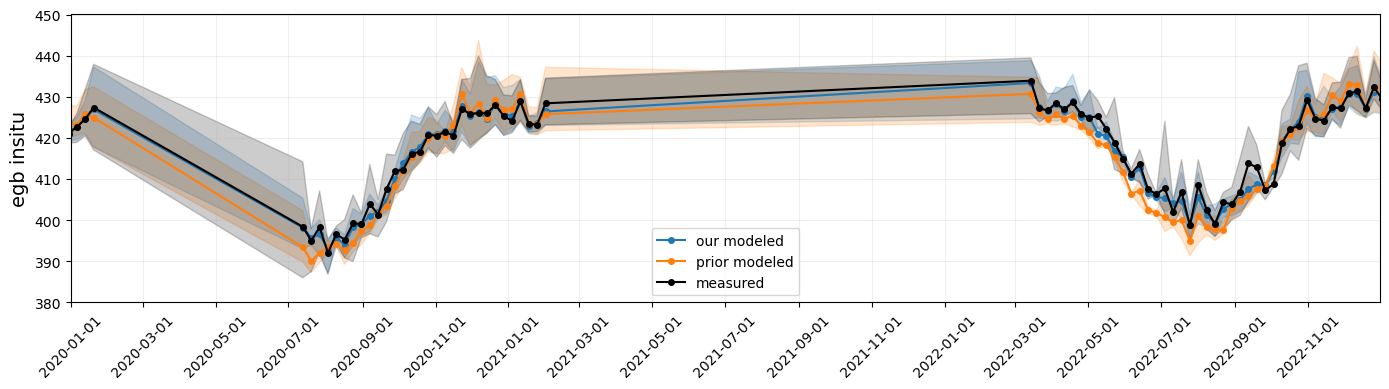

In [42]:
i=0
for station in stations:
    fig,axs=plt.subplots(1,1,figsize=(14,4))
    #fig.suptitle(f'Measured/Modeled In-Situ, {station[4:7]}',fontsize=14)
    default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    temp=inversion.insitu.where(( inversion.insitu.file==station),drop=True)
    temp['diurnal']=temp.real_co2-temp.co2
    temp['co2_modeled_posterior']=temp.posterior_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
    temp['co2_modeled_prior']=temp.prior_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
    temp['co2_modeled_TM5']=temp.ref_RemoteC_IS_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
    weekly=temp.assign_coords(release_week=temp.release_week, release_box_lat=temp.release_box_lat, release_box_lon=temp.release_box_lon)
    if len(temp.pointspec)!=0:
        temp_mean=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).mean()
        temp_max=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).max()
        temp_min=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).min()
        # our posterior
        axs.plot(temp_mean.release_week, (temp_mean.co2_modeled_posterior).mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[0], markersize=4,label='our modeled')
        axs.fill_between(temp_min.release_week, temp_min.co2_modeled_posterior.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.co2_modeled_posterior.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[0], alpha=0.2) 
        # prior
        axs.plot(temp_mean.release_week, temp_mean.co2_modeled_prior.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[1], markersize=4,label='prior modeled')
        axs.fill_between(temp_min.release_week, temp_min.co2_modeled_prior.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.co2_modeled_prior.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[1], alpha=0.2) 
        # measured
        axs.plot(temp_mean.release_week, temp_mean.real_co2.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color='black', markersize=4,label='measured')
        axs.fill_between(temp_min.release_week, temp_min.real_co2.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.real_co2.mean(dim=['release_box_lat', 'release_box_lon']), color='black', alpha=0.2) 
        # TM5-4DVar
        #axs.plot(temp_mean.release_week, temp_mean.co2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color='grey', markersize=4,label='TM5-4DVar modeled', alpha=0.5)
        #axs.fill_between(temp_min.release_week, temp_min.co2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.co2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']), color='grey', alpha=0.1) 
        axs.legend()
    print(station)
    if 'flask' in station:
        label=f'{station[4:7]} flask'
    if 'tower' in station:
        label=f'{station[4:7]} tower'
    if 'pfp' in station:
        label=f'{station[4:7]} PFP'
    if 'surface-insitu' in station:
        label=f'{station[4:7]} insitu'
    axs.set_ylabel(label,fontsize=14)
    axs.set_ylim(380,450)
    axs.grid(visible=True, which='major', axis='both', alpha=0.2)
    axs.set_xticks(pd.date_range(analysis_start_date,analysis_end_date,freq='2MS'))
    axs.tick_params(axis='x', labelrotation=45)
    axs.set_xlim(analysis_start_date,analysis_end_date)
    plt.tight_layout()
    plt.savefig(f'{savefig_IS}/stations/measurement_timeline_IS_modeled_measured_{station}.',bbox_inches='tight')#,transparent=True)
    #plt.show()
    plt.show()
    break


In [31]:
# all stations!
stations=np.unique(all_is_data.file.values)
i=0
for station in stations:
    fig,axs=plt.subplots(1,1,figsize=(10,4))
    #fig.suptitle(f'Measured/Modeled In-Situ, {station[4:7]}',fontsize=14)
    default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    temp=all_is_data.where(( all_is_data.file==station),drop=True)
    temp['diurnal']=temp.real_co2-temp.co2
    temp['co2_modeled_posterior']=temp.posterior_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
    temp['co2_modeled_prior']=temp.prior_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
    temp['co2_modeled_TM5']=temp.ref_RemoteC_IS_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
    weekly=temp.assign_coords(release_week=temp.release_week, release_box_lat=temp.release_box_lat, release_box_lon=temp.release_box_lon)
    if len(temp.pointspec)!=0:
        temp_mean=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).mean()
        temp_max=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).max()
        temp_min=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).min()
        # our posterior
        axs.plot(temp_mean.release_week, (temp_mean.co2_modeled_posterior).mean([ 'release_box_lat', 'release_box_lon']), marker='o', color=default_colors[0], markersize=4,label='our modeled')
        axs.fill_between(temp_mean.release_week, temp_min.co2_modeled_posterior.min([ 'release_box_lat', 'release_box_lon']),temp_max.co2_modeled_posterior.max([ 'release_box_lat', 'release_box_lon']), color=default_colors[0], alpha=0.2) 
        axs.plot(temp_mean.release_week, temp_mean.co2_modeled_prior.mean([ 'release_box_lat', 'release_box_lon']), marker='o', color=default_colors[1], markersize=4,label='prior modeled')
        axs.fill_between(temp_mean.release_week, temp_min.co2_modeled_prior.min([ 'release_box_lat', 'release_box_lon']),temp_max.co2_modeled_prior.max([ 'release_box_lat', 'release_box_lon']), color=default_colors[1], alpha=0.2) 
        axs.plot(temp_mean.release_week, temp_mean.real_co2.mean([ 'release_box_lat', 'release_box_lon']), marker='o', color='black', markersize=4,label='measured')
        axs.fill_between(temp_mean.release_week, temp_min.real_co2.min([ 'release_box_lat', 'release_box_lon']),temp_max.real_co2.max([ 'release_box_lat', 'release_box_lon']), color='black', alpha=0.2) 
           # TM5-4DVar
        #axs.plot(temp_mean.release_week, temp_mean.co2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color='grey', markersize=4,label='TM5-4DVar modeled', alpha=0.5)
        #axs.fill_between(temp_min.release_week, temp_min.co2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.co2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']), color='grey', alpha=0.1) 
        axs.legend()
    print(station)
    if 'flask' in station:
        label=f'{station[4:7]} flask CO$_2$ [ppm]'
    if 'tower' in station:
        label=f'{station[4:7]} tower CO$_2$ [ppm]'
    if 'pfp' in station:
        label=f'{station[4:7]} PFP CO$_2$ [ppm]'
    if 'surface-insitu' in station:
        label=f'{station[4:7]} insitu CO$_2$ [ppm]'
    axs.set_ylabel(label,fontsize=16)
    axs.set_ylim(380,450)
    axs.grid(visible=True, which='major', axis='both', alpha=0.2)
    axs.set_xticks(pd.date_range(analysis_start_date,analysis_end_date,freq='2MS'))

    axs.tick_params(axis='x', labelrotation=45,labelsize =12)
    axs.tick_params(axis='y',labelsize =12)
    axs.set_xticklabels((axs.get_xticklabels()),ha='right')
    axs.set_xlim(analysis_start_date,analysis_end_date)

    plt.tight_layout()
    plt.savefig(f'{savefig_IS}/stations/pdf/measurement_timeline_IS_modeled_measured_{station}.pdf',bbox_inches='tight')#,transparent=True)
    #plt.show()
    plt.close()


co2_amt_surface-pfp_1_allvalid-107magl.nc
co2_amt_tower-insitu_1_allvalid-107magl.nc
co2_bmw_surface-flask_1_representative.nc
co2_bra_surface-insitu_6_allvalid.nc
co2_cps_surface-insitu_6_allvalid.nc
co2_egb_surface-insitu_6_allvalid.nc
co2_esp_surface-insitu_6_allvalid.nc
co2_est_surface-insitu_6_allvalid.nc
co2_etl_surface-insitu_6_allvalid.nc
co2_fsd_surface-insitu_6_allvalid.nc
co2_key_surface-flask_1_representative.nc
co2_lef_tower-insitu_1_allvalid-396magl.nc
co2_lew_surface-pfp_1_allvalid-95magl.nc
co2_llb_surface-insitu_6_allvalid.nc
co2_mwo_surface-pfp_1_allvalid-46magl.nc
co2_omp_surface-insitu_68_allhours.nc
co2_sct_surface-pfp_1_allvalid-305magl.nc
co2_sct_tower-insitu_1_allvalid-305magl.nc
co2_sgp_surface-flask_1_representative.nc
co2_sgp_surface-insitu_64_allvalid-60magl.nc
co2_wbi_surface-pfp_1_allvalid-379magl.nc
co2_wbi_tower-insitu_1_allvalid-379magl.nc
co2_wgc_tower-insitu_1_allvalid-484magl.nc
co2_wkt_tower-insitu_1_allvalid-457magl.nc


## GOSAT

In [16]:
savefig_GOSAT='figures_2/3years/model_anaylsis/measurements/GOSAT/'

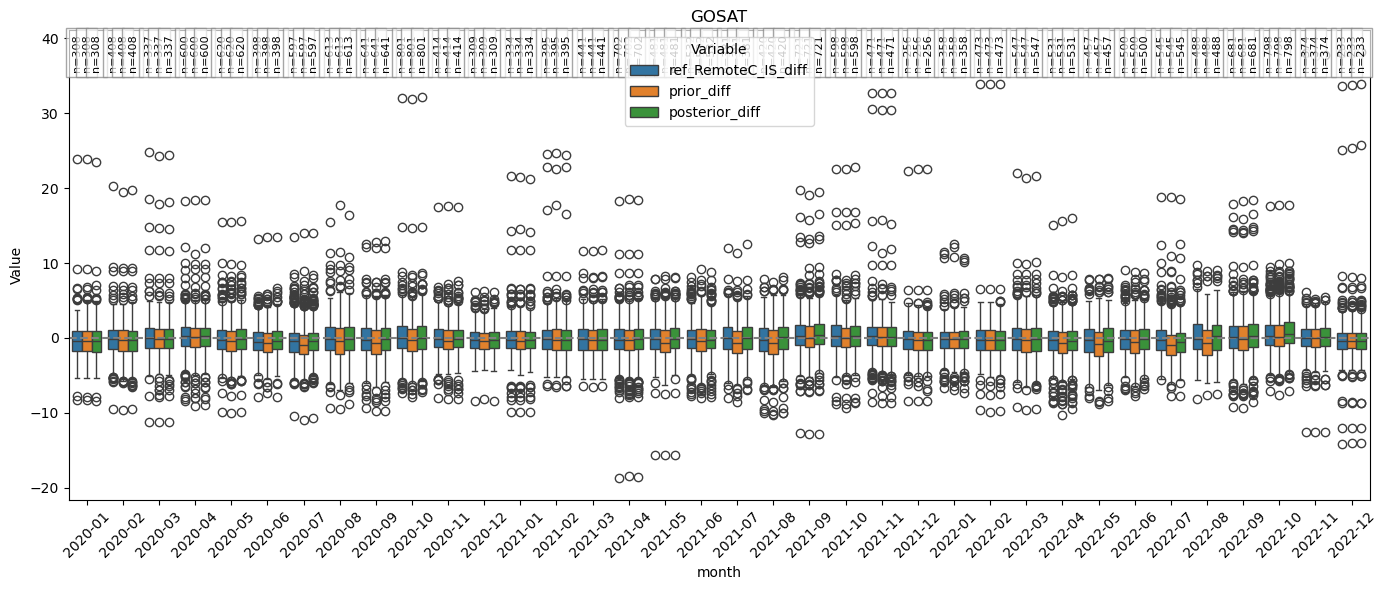

In [97]:

vars = ['ref_RemoteC_IS_diff', 'prior_diff', 'posterior_diff']
rows = []
for year in [2020,2021,2022]:
    for month in range(12):
        temp = inversion.gosat
        temp = temp.where((temp.release_day.dt.month == month+1)&(temp.release_day.dt.year==year), drop=True)
        for v in vars:
            values = temp[v].values.flatten()
            for val in values:
                if not np.isnan(val):
                    rows.append({'month': dt.date(year,month+1,1).strftime("%Y-%m"), 'Variable': v, 'Value': val})
df = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(14,6))

sns.boxplot(data=df, x='month', y='Value', hue='Variable', ax=ax)
plt.axhline(0, color='gray', linestyle='--')

# Calculate counts
counts = (df.groupby(['month', 'Variable']).size().reset_index(name='n'))

# Get plotting order
month = df['month'].unique()
variables = df['Variable'].unique()

# Width offsets used internally by seaborn
offsets = [-0.27, 0, 0.27]

for i, month in enumerate(month):
    for j, variable in enumerate(variables):
        n = counts[(counts['month'] == month) &
                (counts['Variable'] == variable)]['n'].values
        if len(n) > 0:
            xpos = i + offsets[j]
            ypos = df['Value'].max() * 0.93
            ax.text(xpos, ypos, f'n={n[0]}',ha='center', va='bottom',bbox=dict(facecolor='white', alpha=0.7, edgecolor='grey'), fontsize=8, rotation=90)
ax.tick_params(axis='x', labelrotation=45)
plt.title('GOSAT')
plt.tight_layout()
plt.savefig(f'{savefig_GOSAT}/boxplot_gosat_timeseries')
plt.show()
    

(34, 48)
(-126, -108)
(34, 48)
(-108, -90)
(34, 48)
(-90, -70)
(20, 34)
(-126, -108)


/tmp/ipykernel_3620261/4293595858.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')


(20, 34)
(-108, -90)


/tmp/ipykernel_3620261/4293595858.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')


(20, 34)
(-90, -70)


/tmp/ipykernel_3620261/4293595858.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')


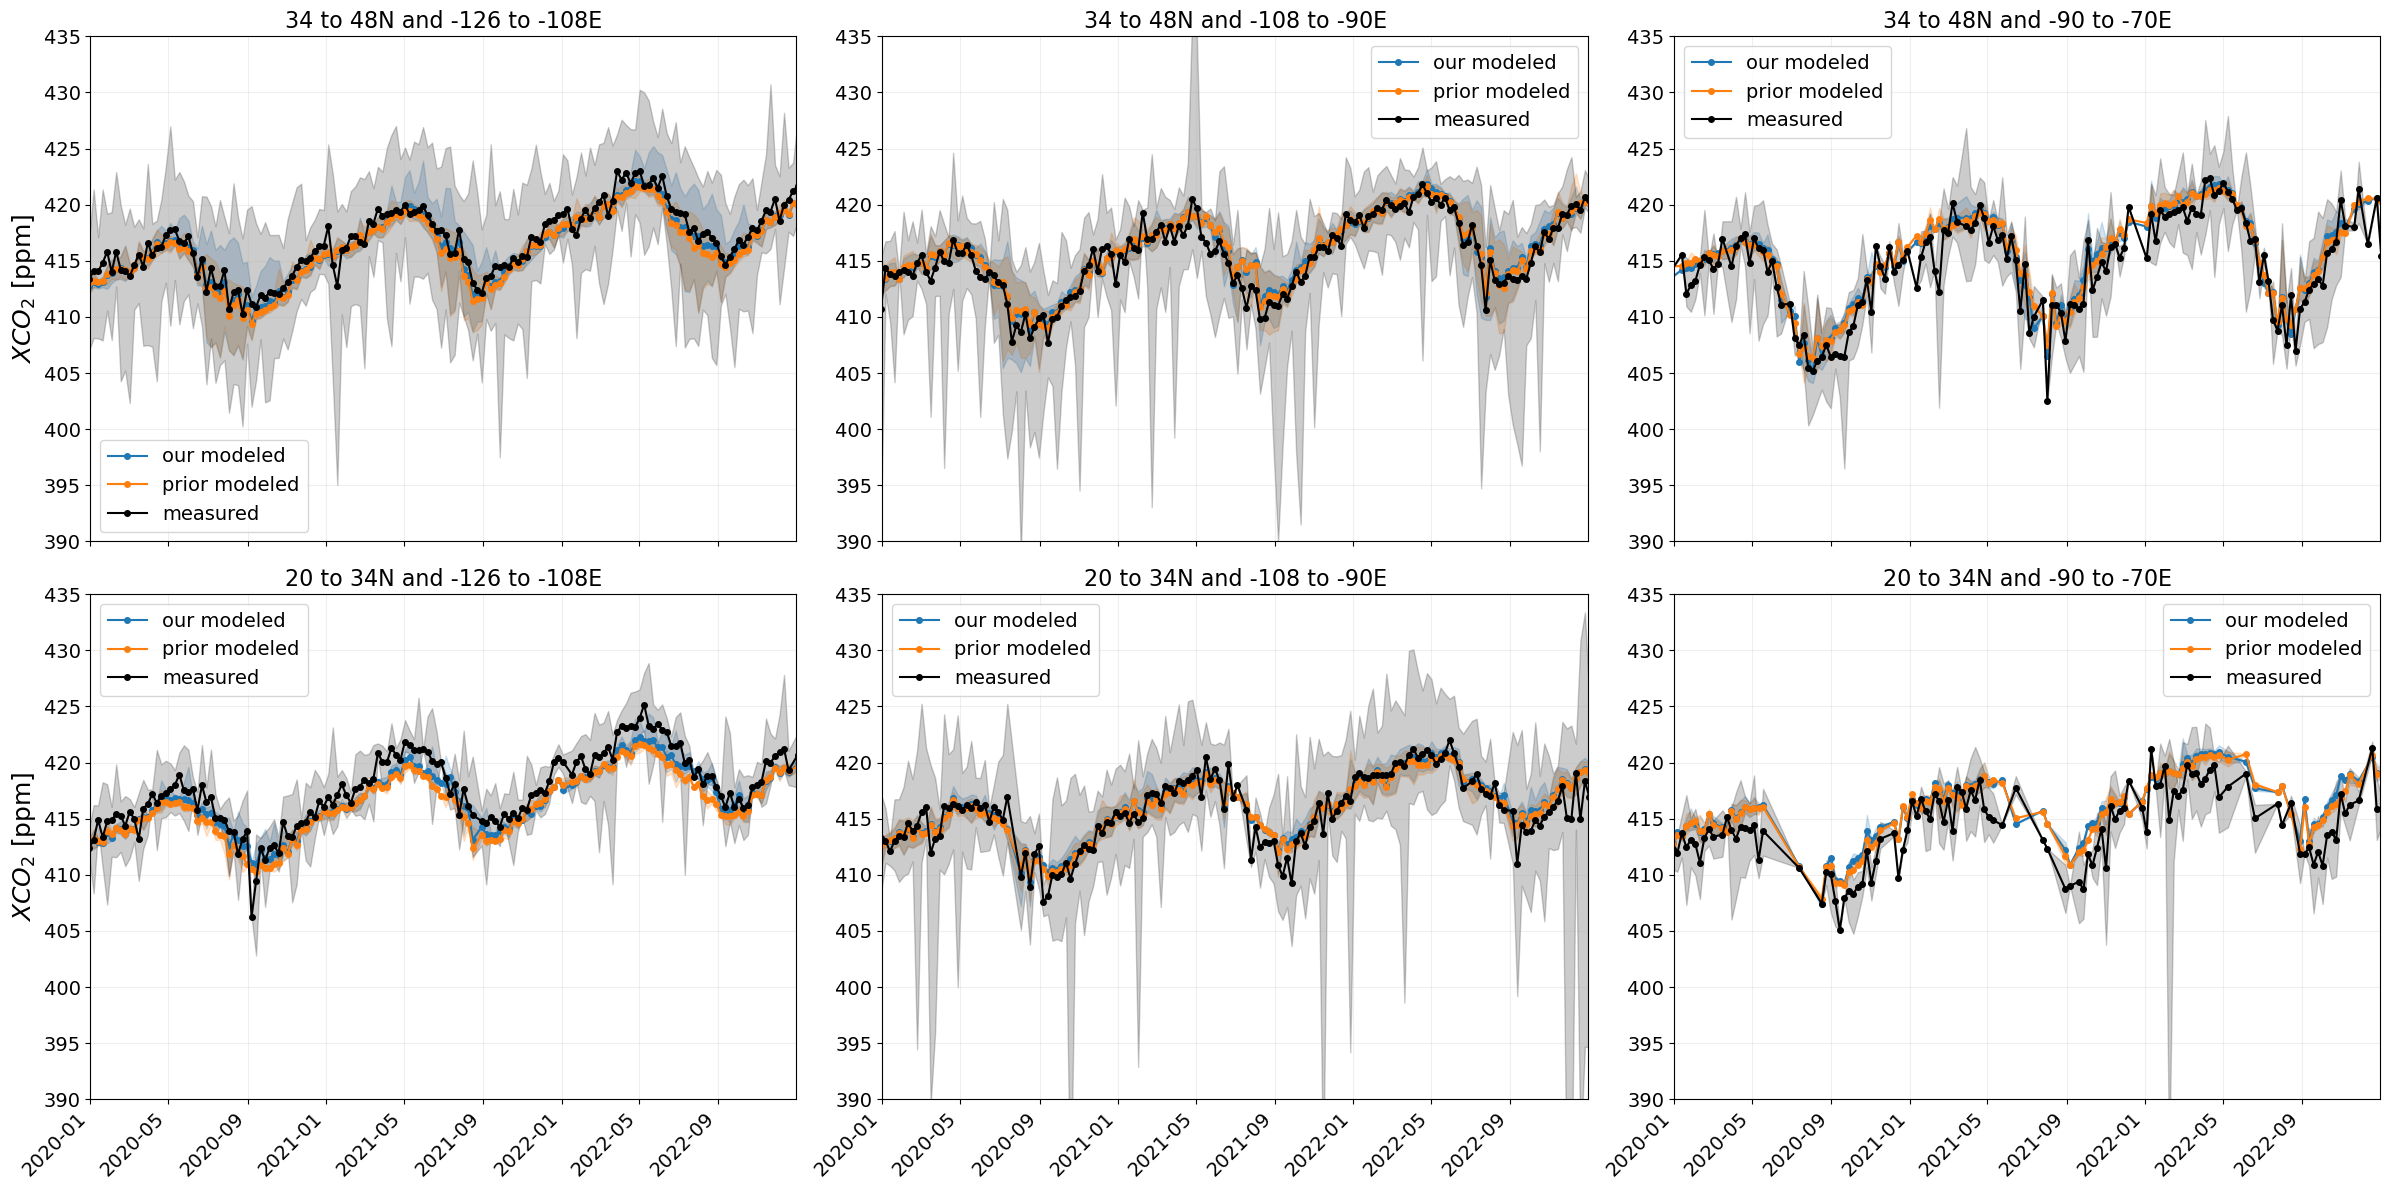

In [25]:
fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(24,12))
#fig.suptitle('Measured/Modeled GOSAT',fontsize=14)
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
for i in range(n_regions[0]): #lat(0.02, plt.cm.Reds(0.60)),
    for j in range(n_regions[1]): #lon
        print((regions_lat[-i-2],regions_lat[-i-1]))
        print((regions_lon[j],regions_lon[j+1]))
        temp=inversion.gosat.where(((inversion.gosat.release_box_lat>= regions_lat[-i-2]) &(inversion.gosat.release_box_lat<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.release_box_lon>= regions_lon[j]) &(temp.release_box_lon<regions_lon[j+1])),drop=True)
        temp['diurnal']=temp.real_xco2-temp.xco2
        temp['xco2_modeled_posterior']=temp.posterior_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
        temp['xco2_modeled_prior']=temp.prior_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
        temp['xco2_modeled_TM5']=temp.ref_RemoteC_IS_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
        weekly=temp.assign_coords(release_week=temp.release_week, release_box_lat=temp.release_box_lat, release_box_lon=temp.release_box_lon)
        if len(temp.pointspec)!=0:
            temp_mean=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).mean()
            temp_max=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).max()
            temp_min=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).min()
            axs[i,j].plot(temp_mean.release_week, (temp_mean.xco2_modeled_posterior).mean([ 'release_box_lat', 'release_box_lon']), marker='o', color=default_colors[0], markersize=4,label='our modeled')
            axs[i,j].fill_between(temp_mean.release_week, temp_min.xco2_modeled_posterior.min([ 'release_box_lat', 'release_box_lon']),temp_max.xco2_modeled_posterior.max([ 'release_box_lat', 'release_box_lon']), color=default_colors[0], alpha=0.2) 
            axs[i,j].plot(temp_mean.release_week, temp_mean.xco2_modeled_prior.mean([ 'release_box_lat', 'release_box_lon']), marker='o', color=default_colors[1], markersize=4,label='prior modeled')
            axs[i,j].fill_between(temp_mean.release_week, temp_min.xco2_modeled_prior.min([ 'release_box_lat', 'release_box_lon']),temp_max.xco2_modeled_prior.max([ 'release_box_lat', 'release_box_lon']), color=default_colors[1], alpha=0.2) 
            axs[i,j].plot(temp_mean.release_week, temp_mean.real_xco2.mean([ 'release_box_lat', 'release_box_lon']), marker='o', color='black', markersize=4,label='measured')
            axs[i,j].fill_between(temp_mean.release_week, temp_min.real_xco2.min([ 'release_box_lat', 'release_box_lon']),temp_max.real_xco2.max([ 'release_box_lat', 'release_box_lon']), color='black', alpha=0.2) 
            #axs[i,j].plot(temp_mean.release_week, temp_mean.xco2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[3], markersize=4,label='TM5-4DVar modeled')
            #axs[i,j].fill_between(temp_min.release_week, temp_min.xco2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.xco2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[3], alpha=0.2) 
            axs[i,j].legend()
            
        axs[i,j].set_ylim(390,435)
        axs[i,j].grid(visible=True, which='major', axis='both', alpha=0.2)
        axs[i,j].set_xlim(analysis_start_date,analysis_end_date)
        if j==0:
            axs[i,j].set_ylabel('$XCO_2$ [ppm]',fontsize=18)        
        axs[i,j].legend(fontsize=14)
        if i==1:
            axs[i,j].tick_params(axis='x', labelrotation=45,labelsize =14)
            axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
        else:
            axs[i,j].tick_params(labelbottom=False)                   
        axs[i,j].tick_params(axis='y', labelsize =14)
        axs[i,j].grid(visible=True, which='major', axis='both', alpha=0.2)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E",fontsize=16)

plt.tight_layout()
plt.savefig(f'{savefig_GOSAT}/regional_measurement_timeline_GOSAT_modeled_measured.pdf',bbox_inches='tight')#,transparent=True)
plt.show()
#plt.close()savefig_GOSAT='figures_2/3years/model_anaylsis/measurements/GOSAT/'

In [22]:
weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).max().max([ 'release_box_lat', 'release_box_lon'])

<xarray.Dataset> Size: 78kB
Dimensions:                                                (release_week: 183)
Coordinates:
  * release_week                                           (release_week) datetime64[ns] 1kB ...
    height                                                 float32 4B 30.0
Data variables: (12/52)
    release_num                                            (release_week) float64 1kB ...
    release_day                                            (release_week) datetime64[ns] 1kB ...
    release_time                                           (release_week) datetime64[ns] 1kB ...
    release_lat                                            (release_week) float64 1kB ...
    release_lon                                            (release_week) float64 1kB ...
    xco2                                                   (release_week) float64 1kB ...
    ...                                                     ...
    ref_MIROC_diff                                         (release_week) float64 1kB ...
    ref_NTFVAR_diff                                        (release_week) float64 1kB ...
    diurnal                                                (release_week) float64 1kB ...
    xco2_modeled_posterior                                 (release_week) float64 1kB ...
    xco2_modeled_prior                                     (release_week) float64 1kB ...
    xco2_modeled_TM5                                       (release_week) float64 1kB ...

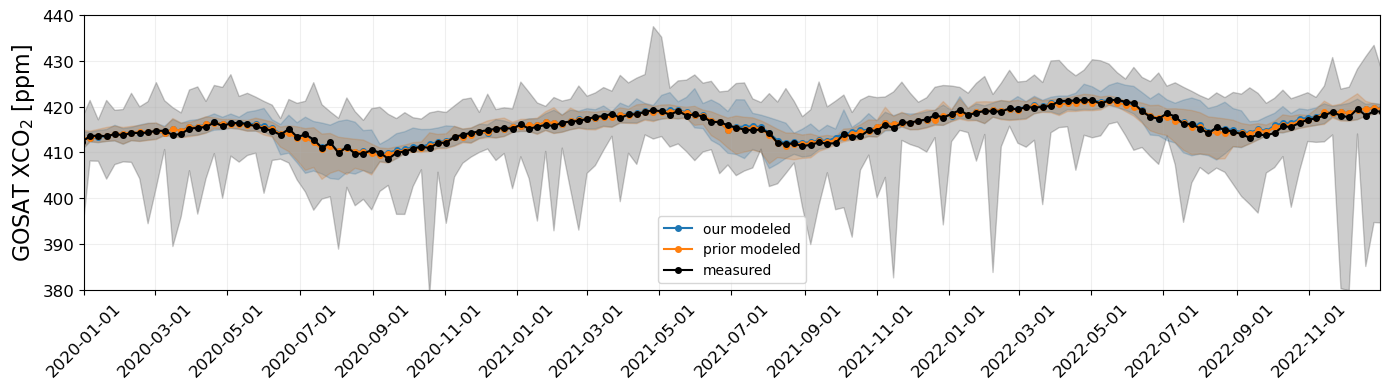

In [27]:
fig,axs=plt.subplots(1,1,figsize=(14,4))
#fig.suptitle('Measured/Modeled GOSAT',fontsize=14)
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

temp=inversion.gosat.where(((inversion.gosat.release_box_lat>= analy_region_lat[0]) &(inversion.gosat.release_box_lat<=analy_region_lat[1])),drop=True)
temp=temp.where(((temp.release_box_lon>= analy_region_lon[0]) &(temp.release_box_lon<=analy_region_lon[1])),drop=True)
temp['diurnal']=temp.real_xco2-temp.xco2
temp['xco2_modeled_posterior']=temp.posterior_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
temp['xco2_modeled_prior']=temp.prior_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
temp['xco2_modeled_TM5']=temp.ref_RemoteC_IS_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
weekly=temp.assign_coords(release_week=temp.release_week, release_box_lat=temp.release_box_lat, release_box_lon=temp.release_box_lon)
if len(temp.pointspec)!=0:
    temp_mean=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).mean()
    temp_max=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).max()
    temp_min=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).min()
    axs.plot(temp_mean.release_week, (temp_mean.xco2_modeled_posterior).mean([ 'release_box_lat', 'release_box_lon']), marker='o', color=default_colors[0], markersize=4,label='our modeled')
    axs.fill_between(temp_mean.release_week, temp_min.xco2_modeled_posterior.min([ 'release_box_lat', 'release_box_lon']),temp_max.xco2_modeled_posterior.max([ 'release_box_lat', 'release_box_lon']), color=default_colors[0], alpha=0.2) 
    axs.plot(temp_mean.release_week, temp_mean.xco2_modeled_prior.mean([ 'release_box_lat', 'release_box_lon']), marker='o', color=default_colors[1], markersize=4,label='prior modeled')
    axs.fill_between(temp_mean.release_week, temp_min.xco2_modeled_prior.min([ 'release_box_lat', 'release_box_lon']),temp_max.xco2_modeled_prior.max([ 'release_box_lat', 'release_box_lon']), color=default_colors[1], alpha=0.2) 
    axs.plot(temp_mean.release_week, temp_mean.real_xco2.mean([ 'release_box_lat', 'release_box_lon']), marker='o', color='black', markersize=4,label='measured')
    axs.fill_between(temp_mean.release_week, temp_min.real_xco2.min([ 'release_box_lat', 'release_box_lon']),temp_max.real_xco2.max([ 'release_box_lat', 'release_box_lon']), color='black', alpha=0.2) 
    #axs.plot(temp_mean.release_week, temp_mean.xco2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[3], markersize=4,label='TM5-4DVar modeled')
    #axs.fill_between(temp_min.release_week, temp_min.xco2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.xco2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[3], alpha=0.2) 
    axs.legend()
    
axs.set_ylabel('GOSAT XCO$_2$ [ppm]',fontsize=16)
axs.set_ylim(380,440)

axs.grid(visible=True, which='major', axis='both', alpha=0.2)
axs.set_xticks(pd.date_range(analysis_start_date,analysis_end_date,freq='2MS'))
axs.tick_params(axis='x', labelrotation=45, labelsize=12)
axs.tick_params(axis='y',labelsize =12)
axs.set_xlim(analysis_start_date,analysis_end_date)
plt.tight_layout()
plt.savefig(f'{savefig_GOSAT}/measurement_timeline_GOSAT_modeled_measured.pdf',bbox_inches='tight')#,transparent=True)
plt.show()

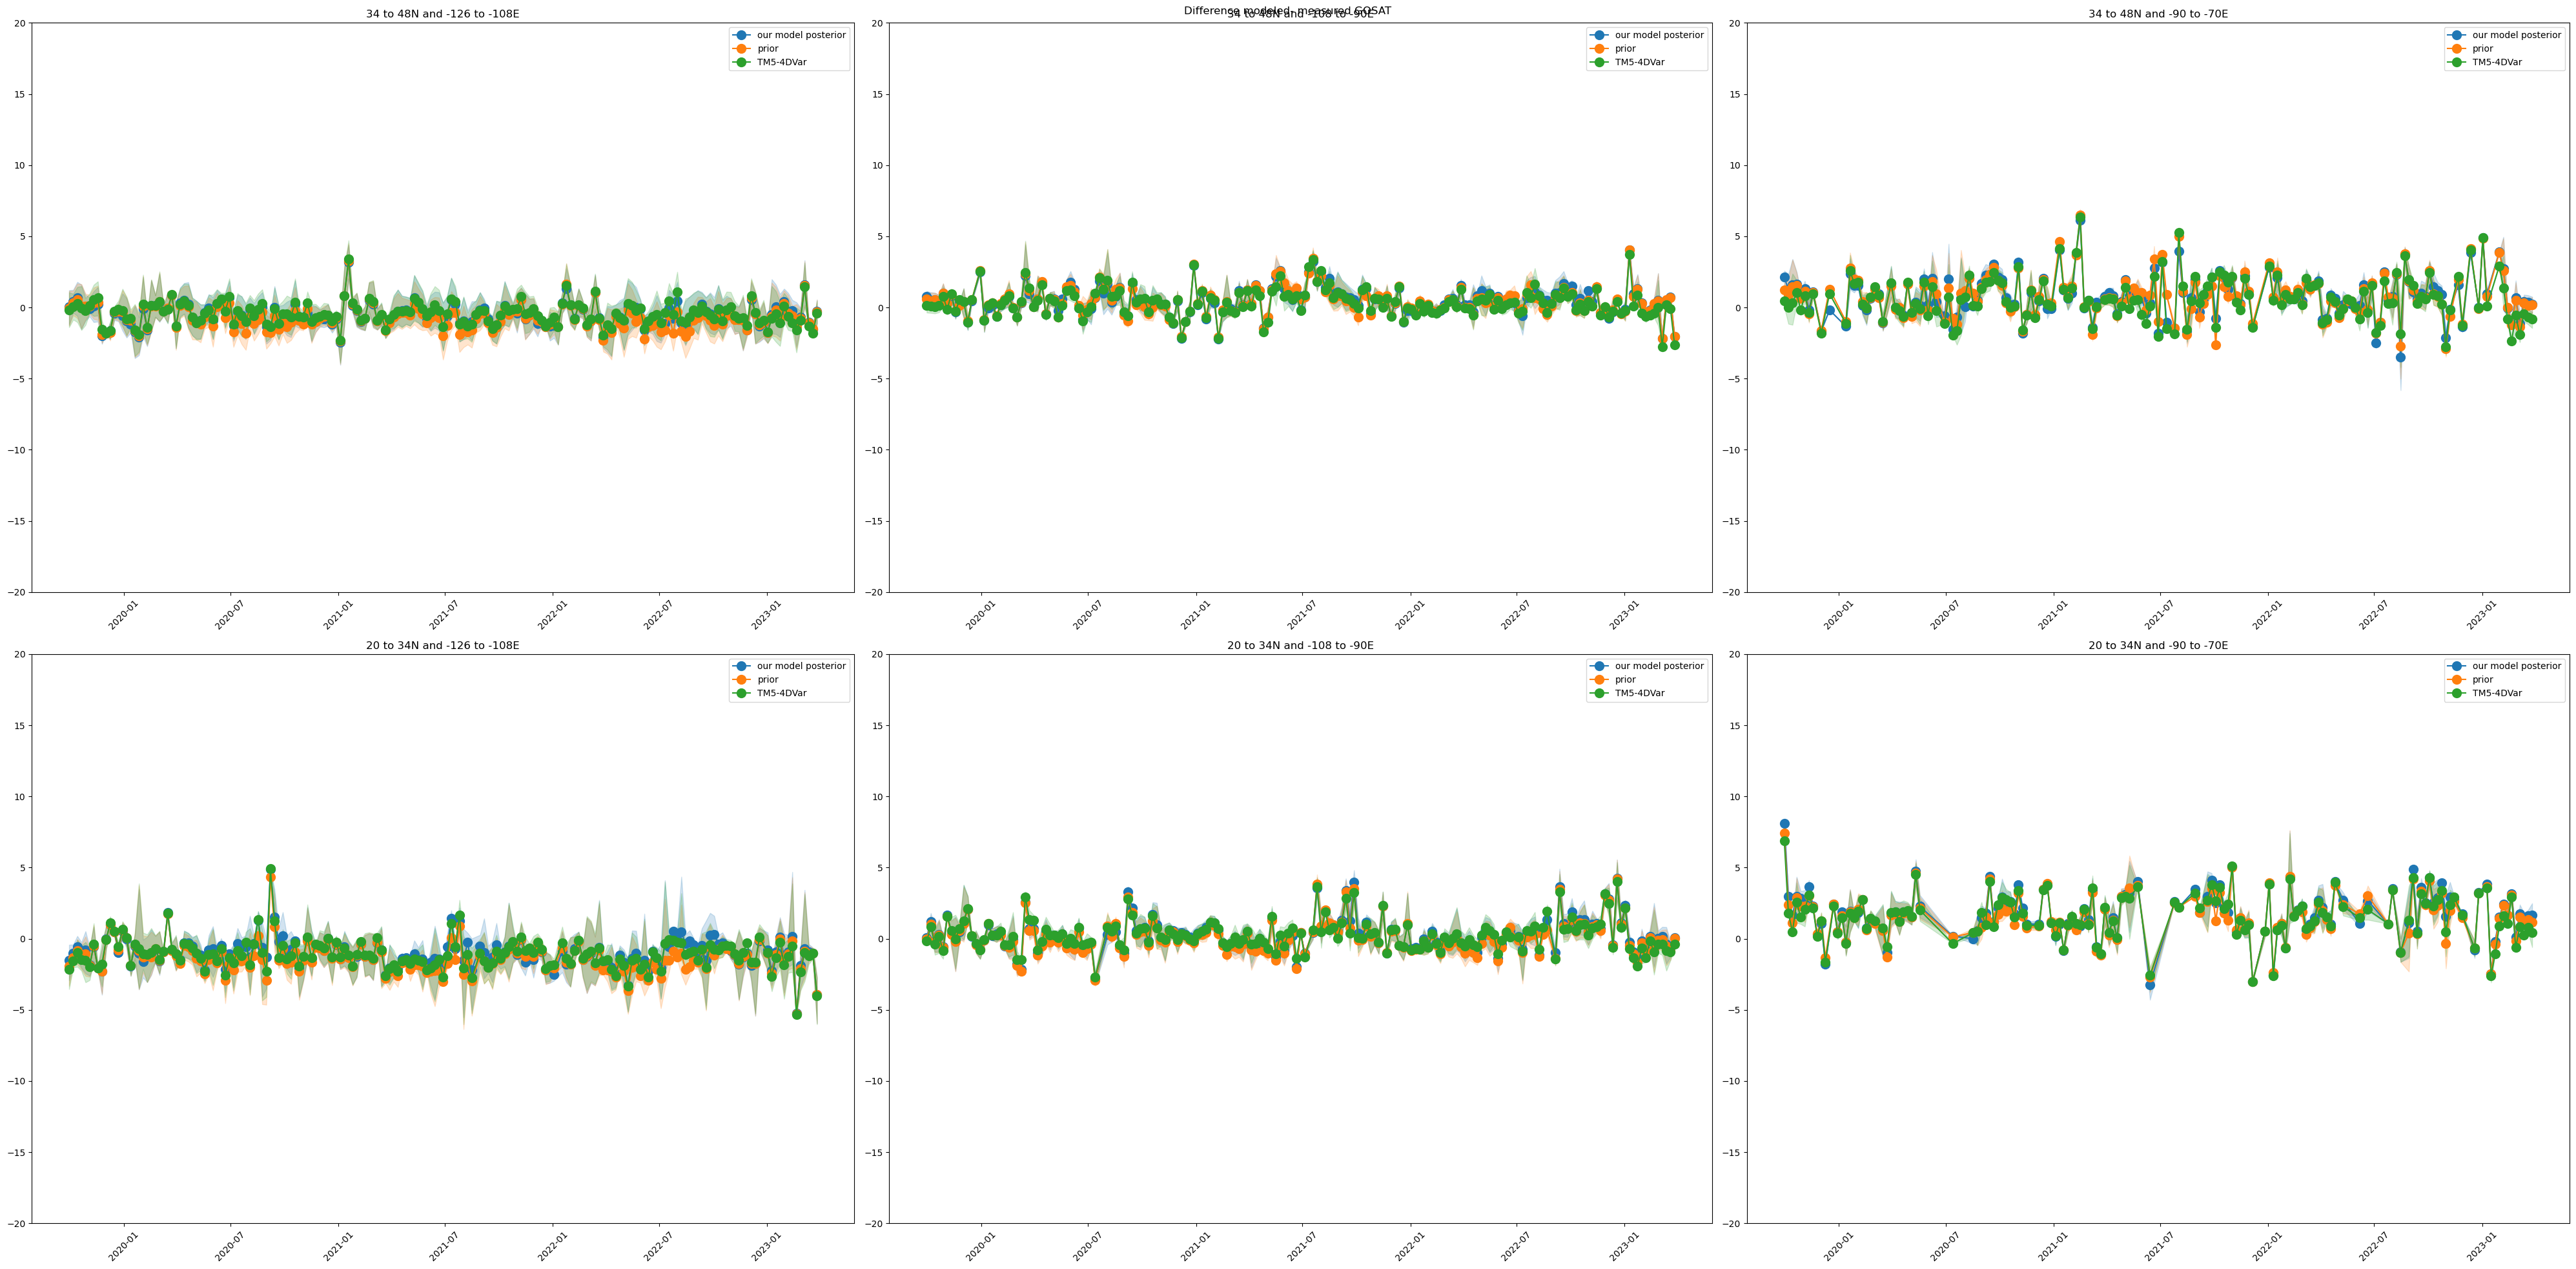

In [105]:
fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(40,20))
fig.suptitle('Difference modeled- measured GOSAT')
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
for i in range(n_regions[0]): #lat(0.02, plt.cm.Reds(0.60)),
    for j in range(n_regions[1]): #lon
        temp=inversion.gosat.where(((inversion.gosat.release_box_lat>= regions_lat[-i-2]) &(inversion.gosat.release_box_lat<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.release_box_lon>= regions_lon[j]) &(temp.release_box_lon<regions_lon[j+1])),drop=True)
        weekly=temp.assign_coords(release_week=temp.release_week, release_box_lat=temp.release_box_lat, release_box_lon=temp.release_box_lon)
        if len(temp.pointspec)!=0:
            temp_mean=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).mean()
            temp_max=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).max()
            temp_min=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).min()
            axs[i,j].plot(temp_mean.release_week, temp_mean.posterior_diff.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[0], markersize=10,label='our model posterior')
            axs[i,j].fill_between(temp_min.release_week, temp_min.posterior_diff.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.posterior_diff.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[0], alpha=0.2) 
            axs[i,j].plot(temp_mean.release_week, temp_mean.prior_diff.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[1], markersize=10,label='prior')
            axs[i,j].fill_between(temp_min.release_week, temp_min.prior_diff.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.prior_diff.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[1], alpha=0.2) 
            axs[i,j].plot(temp_mean.release_week, temp_mean.ref_RemoteC_IS_diff.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[2], markersize=10,label='TM5-4DVar')
            axs[i,j].fill_between(temp_min.release_week, temp_min.ref_RemoteC_IS_diff.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.ref_RemoteC_IS_diff.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[2], alpha=0.2) 
             
        axs[i,j].set_ylabel('')
        axs[i,j].set_ylim(-20,20)
        axs[i,j].legend()
        axs[i,j].tick_params(axis='x', labelrotation=45)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")

plt.tight_layout()
plt.savefig(f'{savefig}/regional_measurement_timeline_GOSAT_diff_modeled_measured.png',bbox_inches='tight')#,transparent=True)
plt.show()
#plt.close()

## TCCON

In [35]:
savefig_TCCON='figures_2/3years/model_anaylsis/measurements/TCCON/'

In [21]:
fig,axs=plt.subplots(1,len(np.unique(inversion.tccon.site_id)),figsize=(17,5))
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
nbins=50
max_min=(-10,10)
for k,site in enumerate(np.unique(inversion.tccon.site_id)):  
    inv=inversion.tccon.where(inversion.tccon.site_id==site,drop=True)
    temp=inv.posterior_diff
    d0=np.round(np.mean(temp).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp)).compute().item(),2)
    d_std=np.round(np.std(temp).compute().item(),2)
    title=fr'{inv.name.values[0]}, $\overline{{d}}={d0}, \overline{{|d|}}={d_abs}, \sigma={d_std}$'
    print(f'TCCON posterior {title}' )
    print(f'N={len(temp)}')
    axs[k].hist(temp,alpha=0.3, bins=nbins,color=default_colors[0], range=max_min)
    axs[k].hist(temp, color=default_colors[0], histtype='step', linewidth=2, bins=nbins, range=max_min,label='Posterior') #, label=label)
    print(site)
    temp=inv.prior_diff
    d0=np.round(np.mean(temp).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp)).compute().item(),2)
    d_std=np.round(np.std(temp).compute().item(),2)
    title=fr'{inv.name.values[0]}, $\overline{{d}}={d0}, \overline{{|d|}}={d_abs}, \sigma={d_std}$'
    print(f'TCCON prior {title}' )
    axs[k].hist(temp,alpha=0.3, bins=nbins,color=default_colors[1], range=max_min)
    axs[k].hist(temp, color=default_colors[1], histtype='step', linewidth=2, bins=nbins, range=max_min,label='Prior') #, label=label)
    
    axs[k].tick_params( labelsize =14)
    axs[k].legend()
    axs[k].set_xlabel('ppm',fontsize=16)
    axs[k].set
    axs[k].set_title(inv.name.values[0], fontsize=18)
plt.tight_layout()
plt.savefig(f'{savefig_TCCON}/histogramm_tccon.pdf',bbox_inches='tight')
plt.close()


TCCON posterior Pasadena, $\overline{d}=-0.88, \overline{|d|}=1.27, \sigma=1.39$
N=934
ci
TCCON prior Pasadena, $\overline{d}=-1.2, \overline{|d|}=1.45, \sigma=1.35$
TCCON posterior Dryden, $\overline{d}=-1.5, \overline{|d|}=2.48, \sigma=2.4$
N=1052
df
TCCON prior Dryden, $\overline{d}=-1.69, \overline{|d|}=2.69, \sigma=2.58$
TCCON posterior Lamont, $\overline{d}=-0.14, \overline{|d|}=0.91, \sigma=1.15$
N=755
oc
TCCON prior Lamont, $\overline{d}=-0.2, \overline{|d|}=0.95, \sigma=1.21$
TCCON posterior Park Falls, $\overline{d}=-0.63, \overline{|d|}=1.21, \sigma=1.36$
N=718
pa
TCCON prior Park Falls, $\overline{d}=-0.64, \overline{|d|}=1.21, \sigma=1.39$


In [34]:
vars = ['ref_RemoteC_IS_diff', 'prior_diff', 'posterior_diff']
rows = []
for i,site in enumerate(np.unique(inversion.tccon.site_id.values)):
    temp = inversion.tccon
    temp = temp.where(temp.site_id == site, drop=True)
    for v in vars:
        values = temp[v].values.flatten()
        for val in values:
            if not np.isnan(val):
                rows.append({'Station': temp.name.values[0], 'Variable': v, 'Value': val})
df = pd.DataFrame(rows)

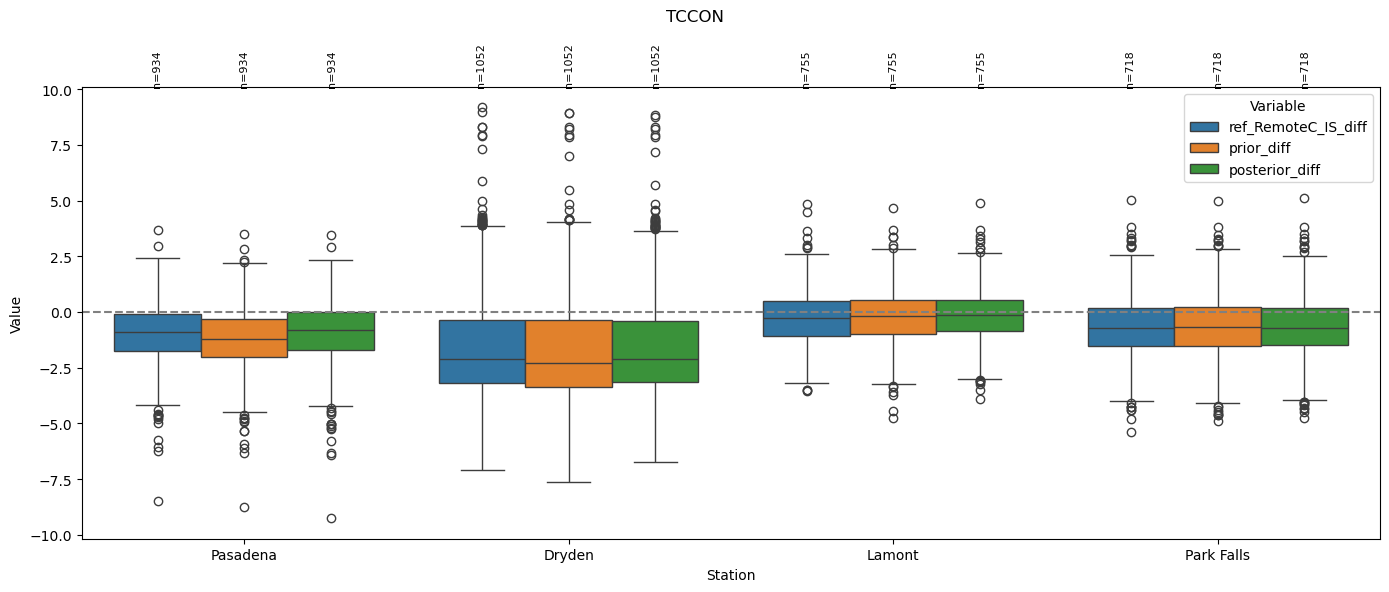

In [35]:

fig, ax = plt.subplots(figsize=(14,6))
fig.suptitle('TCCON')
sns.boxplot(data=df, x='Station', y='Value', hue='Variable', ax=ax)
plt.axhline(0, color='gray', linestyle='--')

# Calculate counts
counts = (df.groupby(['Station', 'Variable']).size().reset_index(name='n'))

# Get plotting order
stations = df['Station'].unique()
variables = df['Variable'].unique()

# Width offsets used internally by seaborn
offsets = [-0.27, 0, 0.27]

for i, station in enumerate(stations):
    for j, variable in enumerate(variables):
        n = counts[(counts['Station'] == station) &
                   (counts['Variable'] == variable)]['n'].values
        if len(n) > 0:
            xpos = i + offsets[j]
            ypos = df['Value'].max() * 1.1
            ax.text(xpos, ypos, f'n={n[0]}',ha='center', va='bottom', fontsize=8, rotation=90)

plt.tight_layout()
plt.savefig(f'{savefig_TCCON}/boxplot_tccon.png')
plt.show()

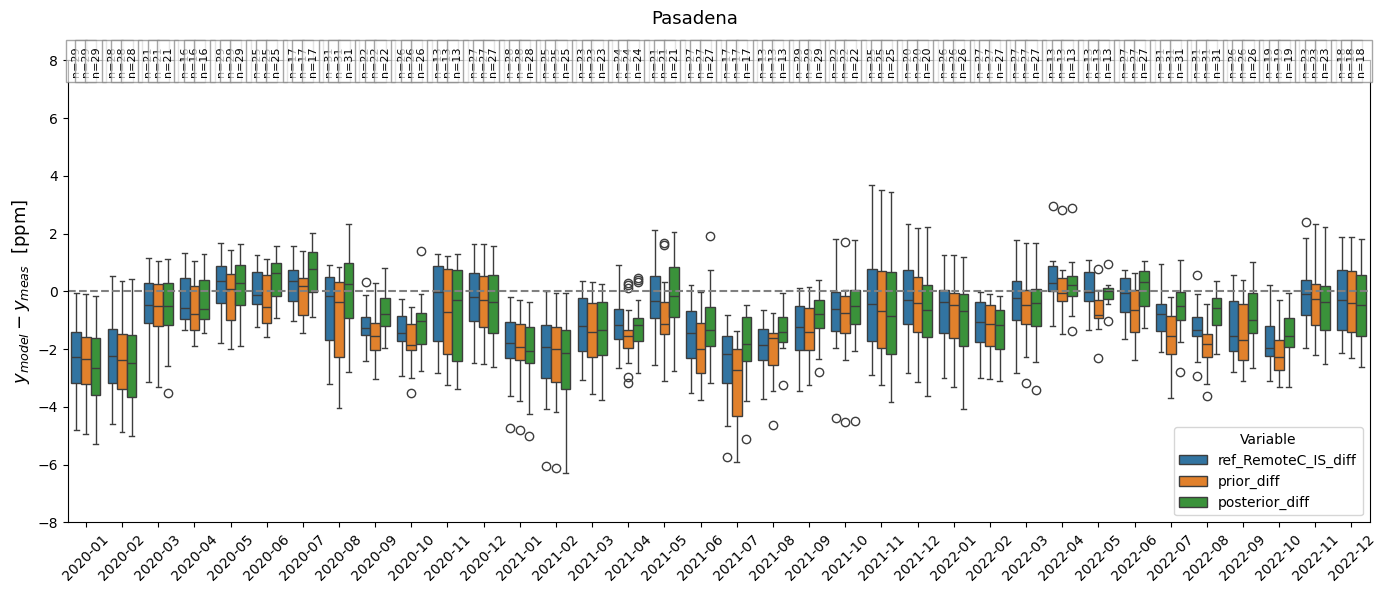

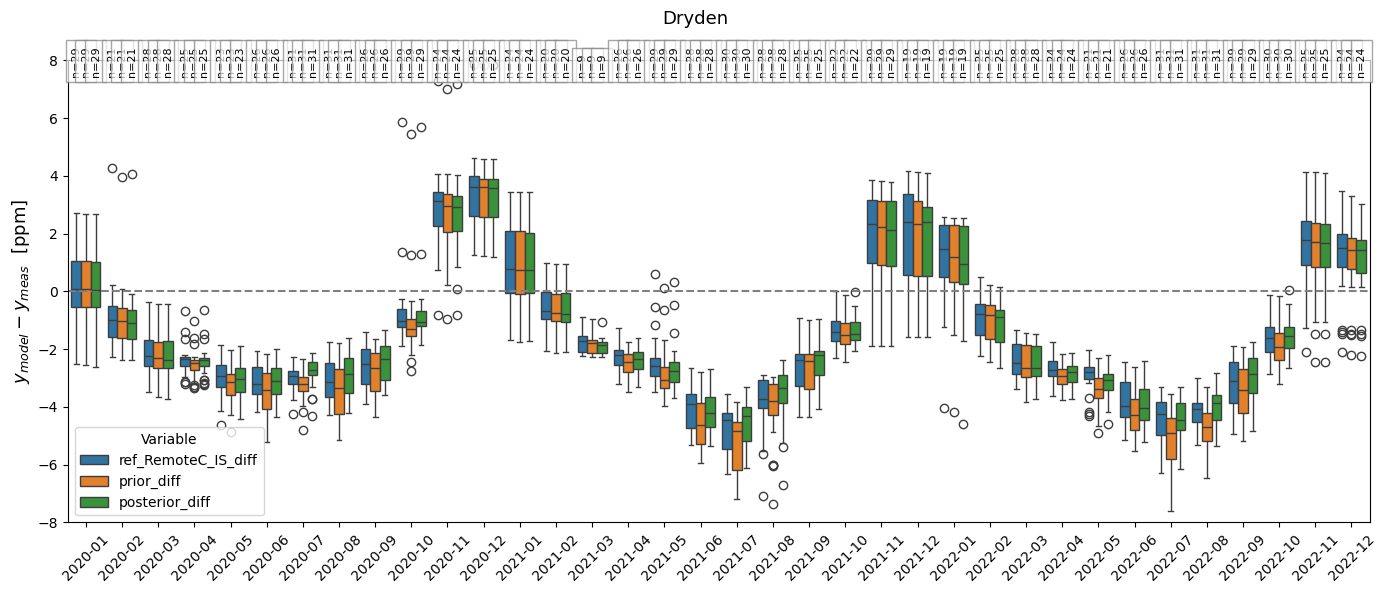

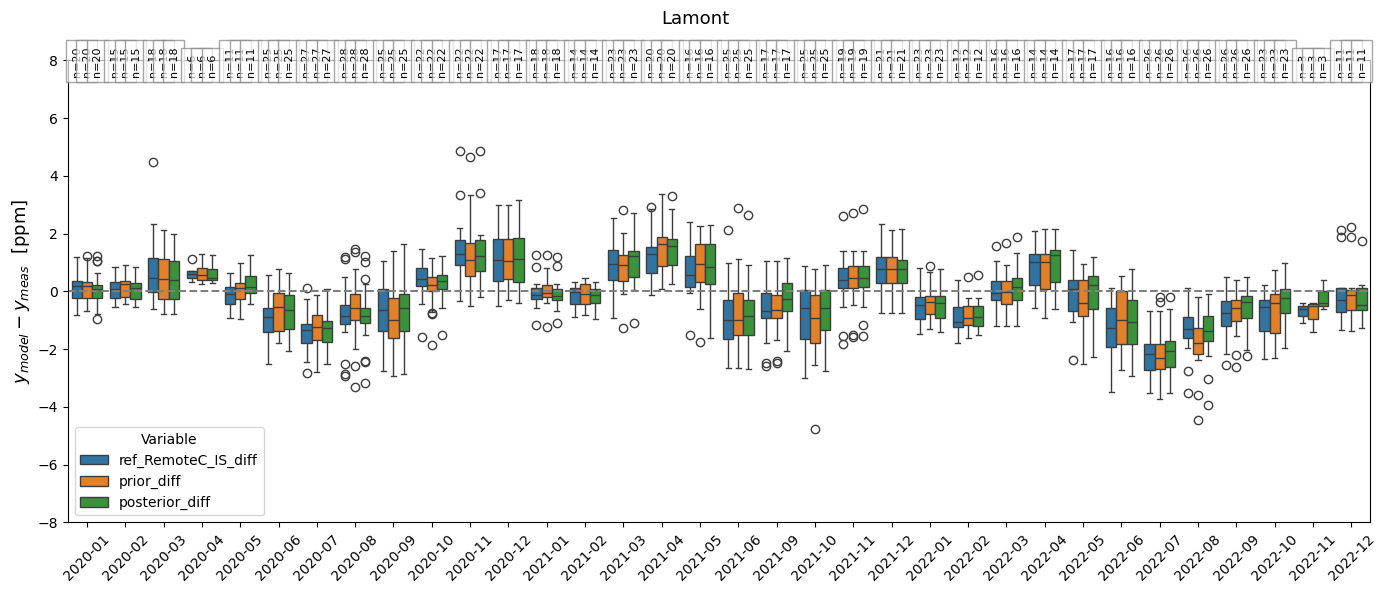

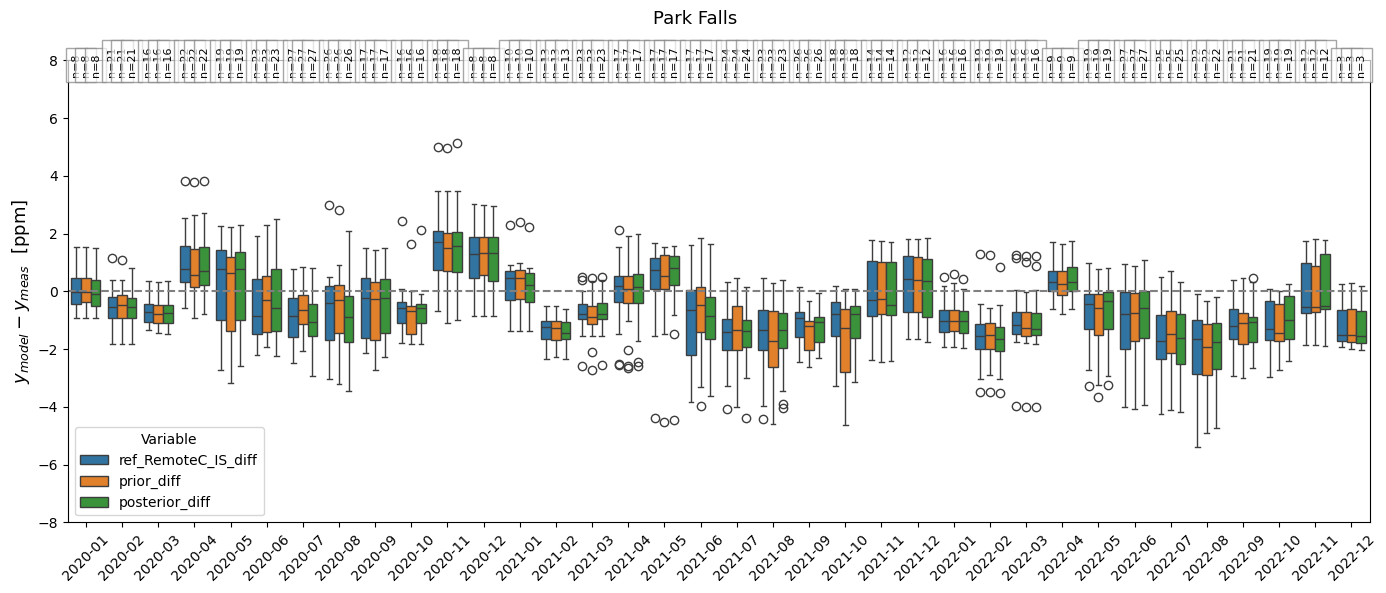

In [36]:
for i,site in enumerate(np.unique(inversion.tccon.site_id.values)):
    temp_site = inversion.tccon
    temp_site=temp_site.where(temp_site.site_id ==site)
    vars = ['ref_RemoteC_IS_diff', 'prior_diff', 'posterior_diff']
    rows = []
    for year in [2020,2021,2022]:
        for month in range(12):
            temp = temp_site
            temp = temp.where((temp.release_day.dt.month == month+1)&(temp.release_day.dt.year==year), drop=True)
            for v in vars:
                values = temp[v].values.flatten()
                for val in values:
                    if not np.isnan(val):
                        rows.append({'month':  dt.date(year,month+1,1).strftime("%Y-%m"), 'Variable': v, 'Value': val})
    df = pd.DataFrame(rows)

    fig, ax = plt.subplots(figsize=(14,6))

    sns.boxplot(data=df, x='month', y='Value', hue='Variable', ax=ax)
    plt.axhline(0, color='gray', linestyle='--')

    # Calculate counts
    counts = (df.groupby(['month', 'Variable']).size().reset_index(name='n'))

    # Get plotting order
    month = df['month'].unique()
    variables = df['Variable'].unique()

    # Width offsets used internally by seaborn
    offsets = [-0.27, 0, 0.27]

    for i, month in enumerate(month):
        for j, variable in enumerate(variables):
            n = counts[(counts['month'] == month) &
                    (counts['Variable'] == variable)]['n'].values
            if len(n) > 0:
                xpos = i + offsets[j]
                ypos = 8 * 0.93
                ax.text(xpos, ypos, f'n={n[0]}',ha='center', va='bottom',bbox=dict(facecolor='white', alpha=0.7, edgecolor='grey'), fontsize=8, rotation=90)
    ax.set_ylim(-8,8)
    ax.tick_params(axis='x', labelrotation=45)
    ax.set_ylabel('$y_{model}-y_{meas}$  [ppm]', fontsize=13)
    ax.set_xlabel('')
    fig.suptitle(temp.name.values[0],fontsize=13)
    plt.tight_layout()
    plt.savefig(f'{savefig_TCCON}/boxplot_{temp.name.values[0]}_timeseries')
    plt.show()
        

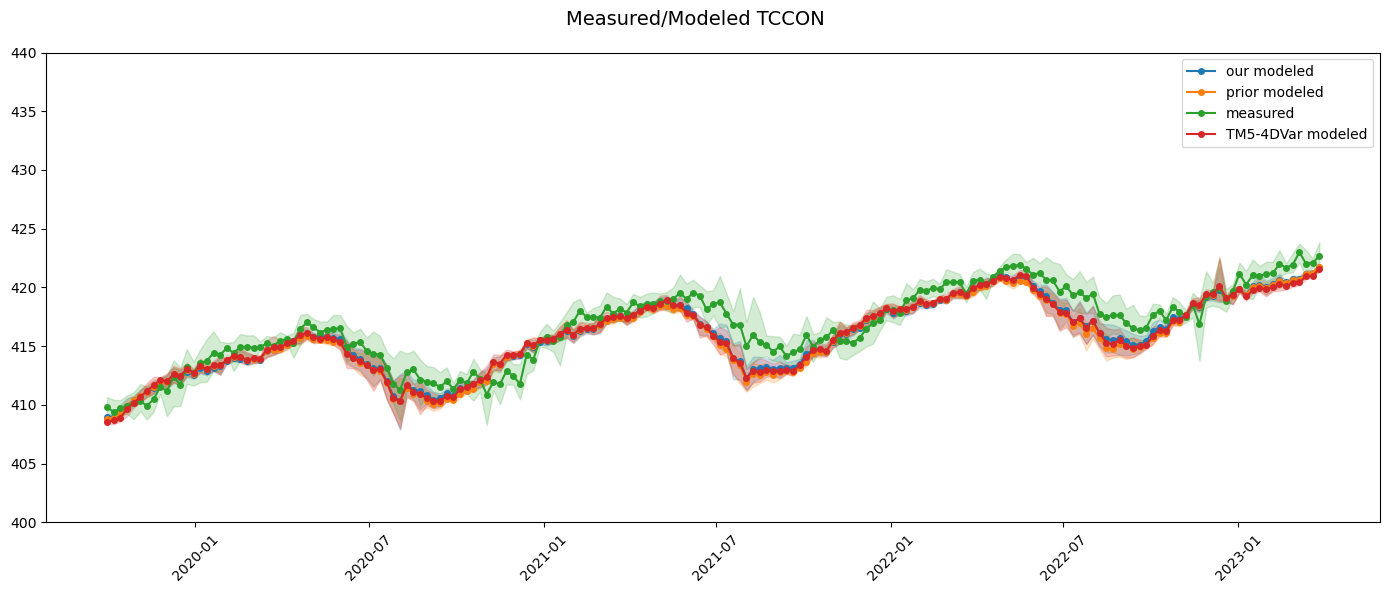

In [40]:
fig,axs=plt.subplots(1,1,figsize=(14,6))
fig.suptitle('Measured/Modeled TCCON',fontsize=14)
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

temp=inversion.tccon.where(((inversion.tccon.release_box_lat>= analy_region_lat[0]) &(inversion.tccon.release_box_lat<=analy_region_lat[1])),drop=True)
temp=temp.where(((temp.release_box_lon>= analy_region_lon[0]) &(temp.release_box_lon<=analy_region_lon[1])),drop=True)
temp['diurnal']=temp.real_xco2-temp.xco2
temp['xco2_modeled_posterior']=temp.posterior_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
temp['xco2_modeled_prior']=temp.prior_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
temp['xco2_modeled_TM5']=temp.ref_RemoteC_IS_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
weekly=temp.assign_coords(release_week=temp.release_week, release_box_lat=temp.release_box_lat, release_box_lon=temp.release_box_lon)
if len(temp.pointspec)!=0:
    temp_mean=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).mean()
    temp_max=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).max()
    temp_min=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).min()
    axs.plot(temp_mean.release_week, (temp_mean.xco2_modeled_posterior).mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[0], markersize=4,label='our modeled')
    axs.fill_between(temp_min.release_week, temp_min.xco2_modeled_posterior.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.xco2_modeled_posterior.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[0], alpha=0.2) 
    axs.plot(temp_mean.release_week, temp_mean.xco2_modeled_prior.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[1], markersize=4,label='prior modeled')
    axs.fill_between(temp_min.release_week, temp_min.xco2_modeled_prior.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.xco2_modeled_prior.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[1], alpha=0.2) 
    axs.plot(temp_mean.release_week, temp_mean.real_xco2.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[2], markersize=4,label='measured')
    axs.fill_between(temp_min.release_week, temp_min.real_xco2.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.real_xco2.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[2], alpha=0.2) 
    axs.plot(temp_mean.release_week, temp_mean.xco2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[3], markersize=4,label='TM5-4DVar modeled')
    axs.fill_between(temp_min.release_week, temp_min.xco2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.xco2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[3], alpha=0.2) 
    axs.legend()
    
axs.set_ylabel('')
axs.set_ylim(400,440)

axs.tick_params(axis='x', labelrotation=45)

plt.tight_layout()
plt.savefig(f'{savefig_TCCON}/measurement_timeline_TCCON_modeled_measured.png',bbox_inches='tight')#,transparent=True)
plt.show()

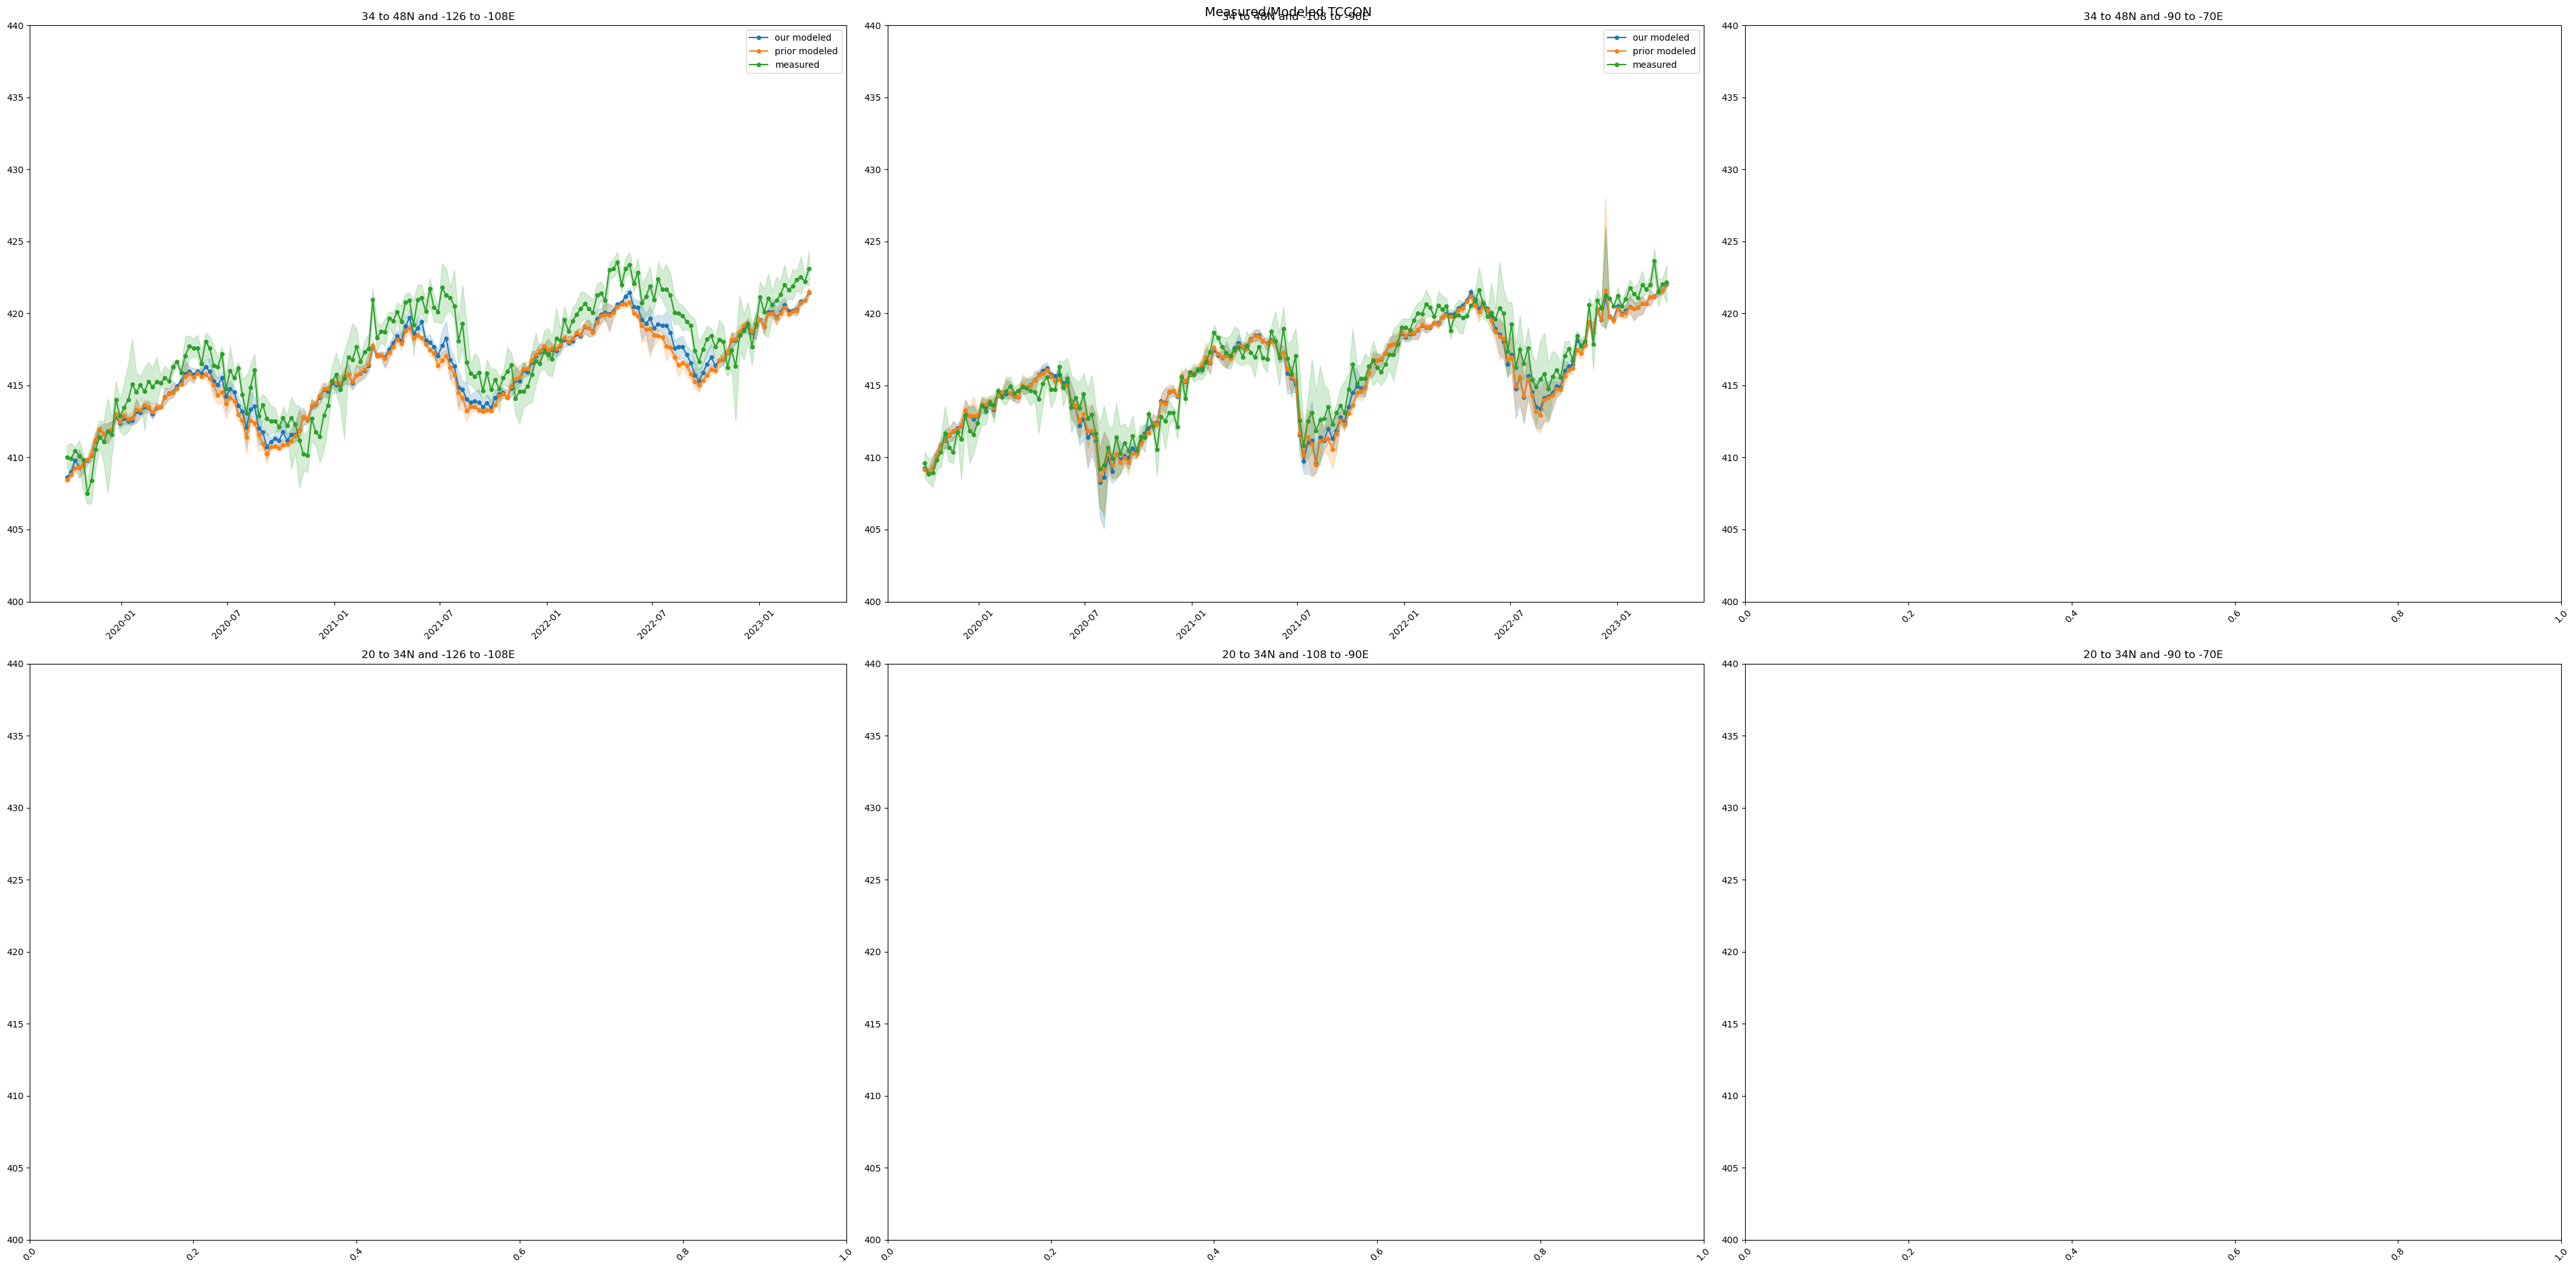

In [41]:
fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(40,20))
fig.suptitle('Measured/Modeled TCCON',fontsize=14)
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
for i in range(n_regions[0]): #lat(0.02, plt.cm.Reds(0.60)),
    for j in range(n_regions[1]): #lon
        temp=inversion.tccon.where(((inversion.tccon.release_box_lat>= regions_lat[-i-2]) &(inversion.tccon.release_box_lat<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.release_box_lon>= regions_lon[j]) &(temp.release_box_lon<regions_lon[j+1])),drop=True)
        temp['diurnal']=temp.real_xco2-temp.xco2
        temp['xco2_modeled_posterior']=temp.posterior_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
        temp['xco2_modeled_prior']=temp.prior_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
        temp['xco2_modeled_TM5']=temp.ref_RemoteC_IS_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
        weekly=temp.assign_coords(release_week=temp.release_week, release_box_lat=temp.release_box_lat, release_box_lon=temp.release_box_lon)
        if len(temp.pointspec)!=0:
            temp_mean=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).mean()
            temp_max=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).max()
            temp_min=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).min()
            axs[i,j].plot(temp_mean.release_week, (temp_mean.xco2_modeled_posterior).mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[0], markersize=4,label='our modeled')
            axs[i,j].fill_between(temp_min.release_week, temp_min.xco2_modeled_posterior.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.xco2_modeled_posterior.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[0], alpha=0.2) 
            axs[i,j].plot(temp_mean.release_week, temp_mean.xco2_modeled_prior.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[1], markersize=4,label='prior modeled')
            axs[i,j].fill_between(temp_min.release_week, temp_min.xco2_modeled_prior.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.xco2_modeled_prior.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[1], alpha=0.2) 
            axs[i,j].plot(temp_mean.release_week, temp_mean.real_xco2.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[2], markersize=4,label='measured')
            axs[i,j].fill_between(temp_min.release_week, temp_min.real_xco2.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.real_xco2.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[2], alpha=0.2) 
            #axs[i,j].plot(temp_mean.release_week, temp_mean.xco2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[3], markersize=4,label='TM5-4DVar modeled')
            #axs[i,j].fill_between(temp_min.release_week, temp_min.xco2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.xco2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[3], alpha=0.2) 
            axs[i,j].legend()
            
        axs[i,j].set_ylabel('')
        axs[i,j].set_ylim(400,440)
        
        axs[i,j].tick_params(axis='x', labelrotation=45)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")

plt.tight_layout()
plt.savefig(f'{savefig}/regional_measurement_timeline_TCCON_modeled_measured.png',bbox_inches='tight')#,transparent=True)
plt.show()
#plt.close()

/tmp/ipykernel_1333899/4154313553.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[i,j].legend()
/tmp/ipykernel_1333899/4154313553.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[i,j].legend()
/tmp/ipykernel_1333899/4154313553.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[i,j].legend()
/tmp/ipykernel_1333899/4154313553.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[i,j].legend()
/tmp/ipykernel_1333899/4154313553.py:22: UserWarning: No artists with labels

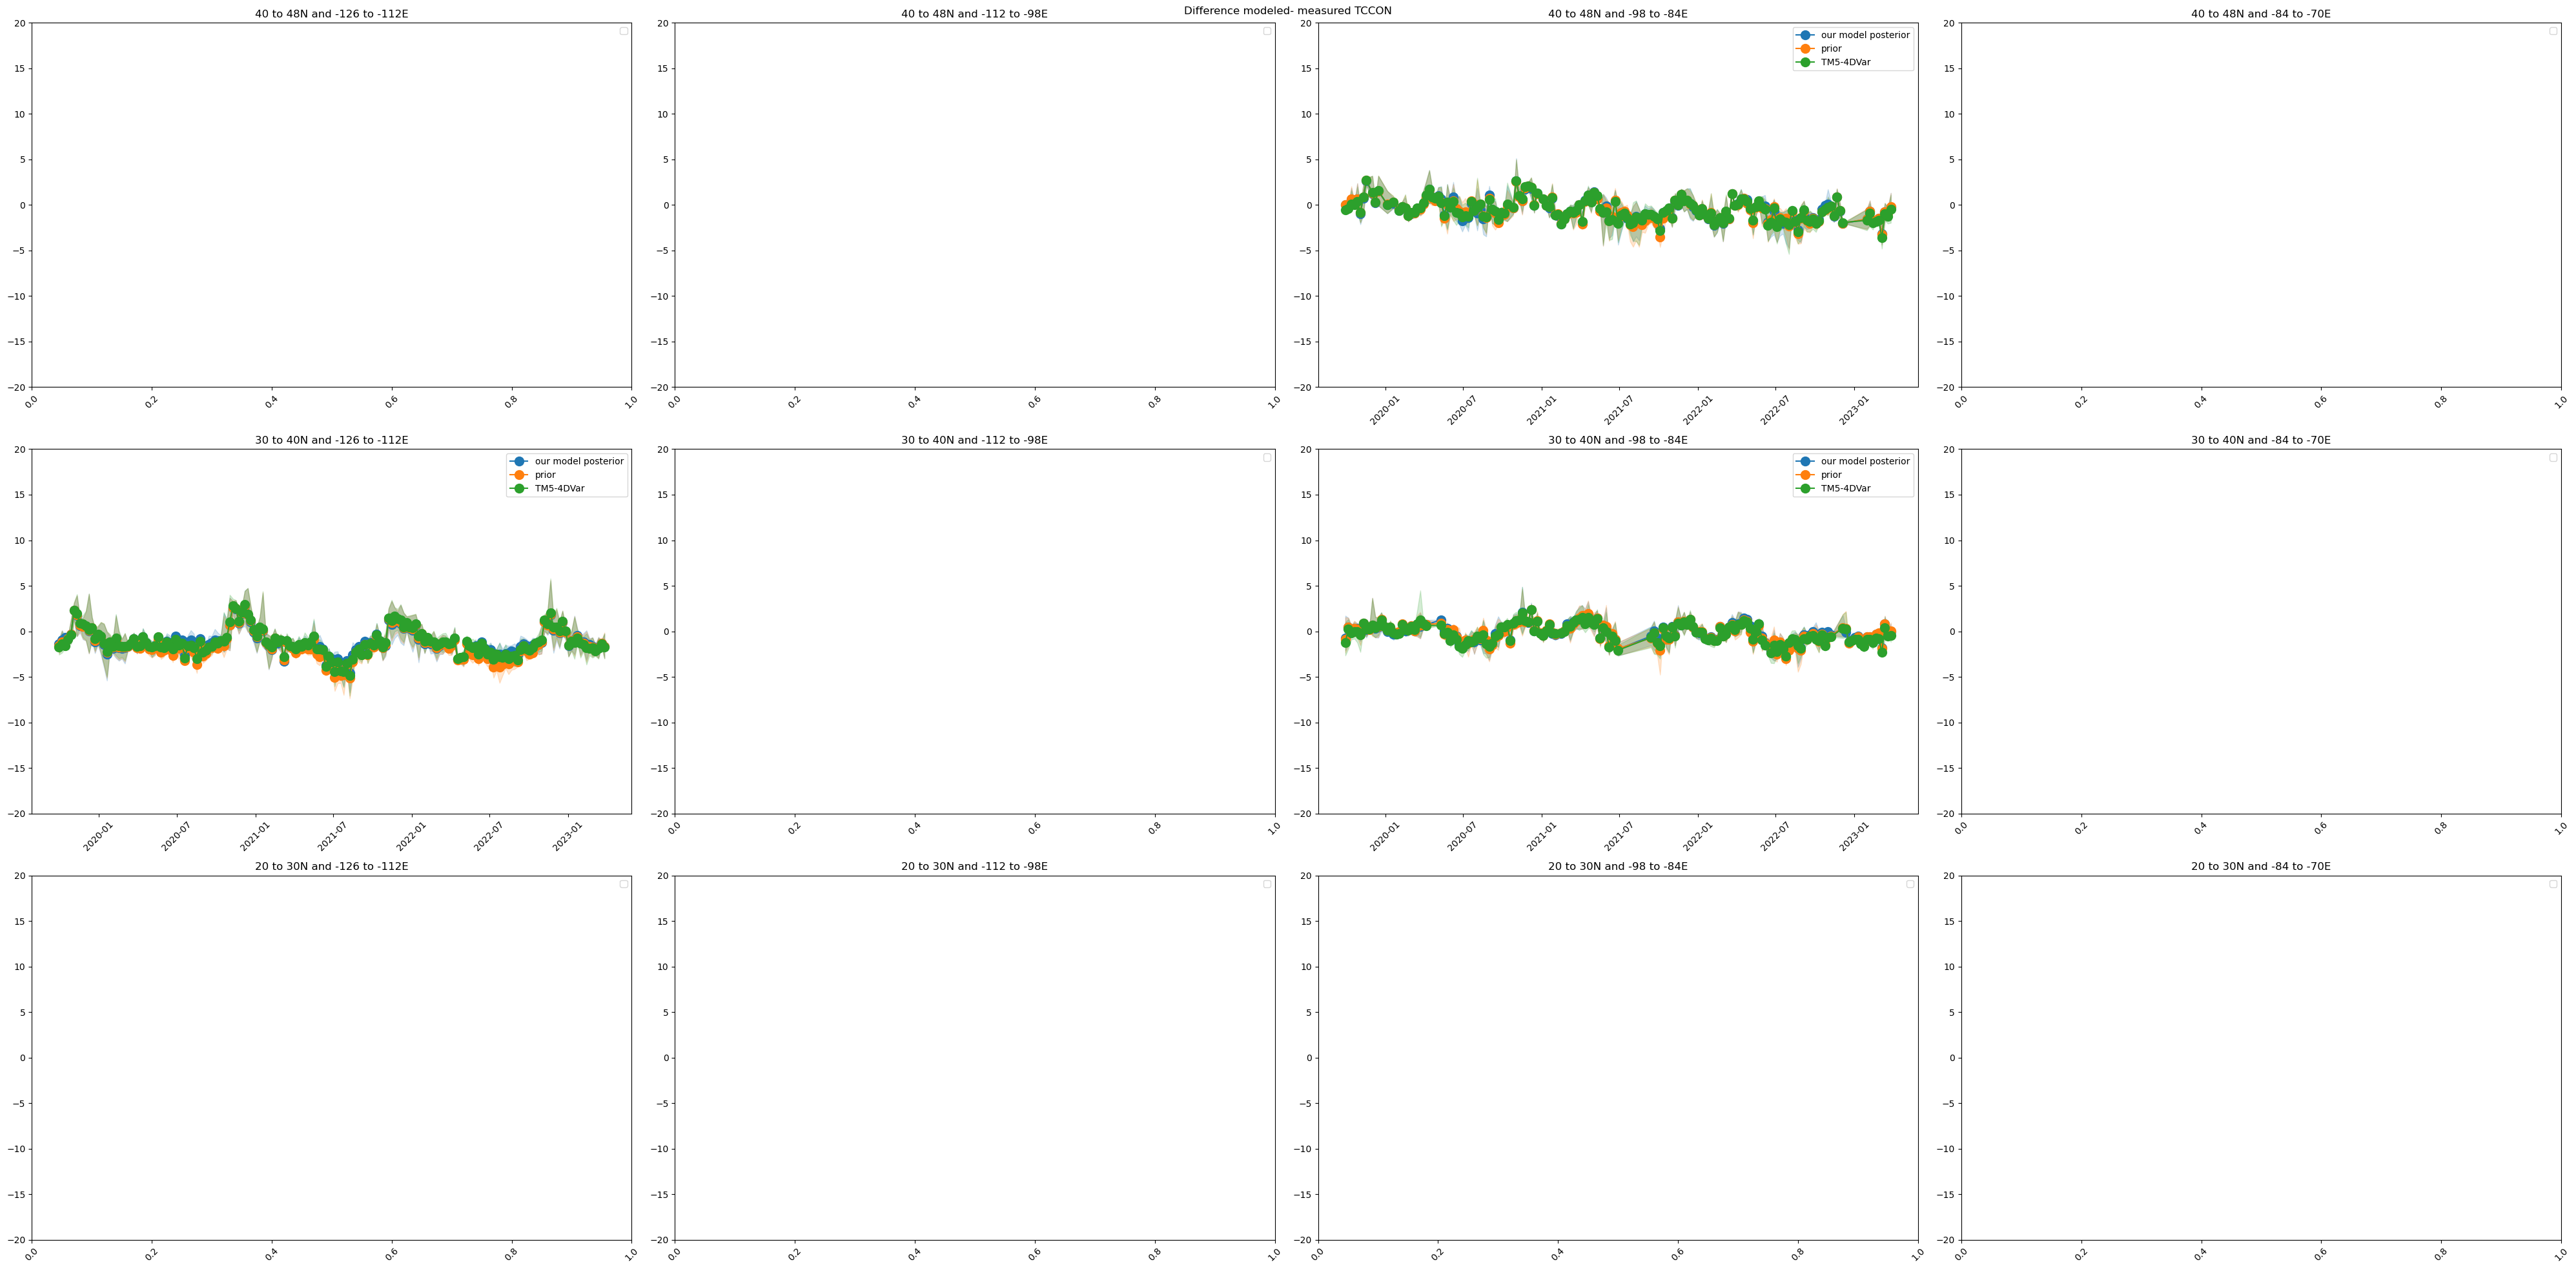

In [163]:
fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(40,20))
fig.suptitle('Difference modeled- measured TCCON')
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
for i in range(n_regions[0]): #lat(0.02, plt.cm.Reds(0.60)),
    for j in range(n_regions[1]): #lon
        temp=inversion.tccon.where(((inversion.tccon.release_box_lat>= regions_lat[-i-2]) &(inversion.tccon.release_box_lat<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.release_box_lon>= regions_lon[j]) &(temp.release_box_lon<regions_lon[j+1])),drop=True)
        weekly=temp.assign_coords(release_week=temp.release_week, release_box_lat=temp.release_box_lat, release_box_lon=temp.release_box_lon)
        if len(temp.pointspec)!=0:
            temp_mean=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).mean()
            temp_max=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).max()
            temp_min=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).min()
            axs[i,j].plot(temp_mean.release_week, temp_mean.posterior_diff.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[0], markersize=10,label='our model posterior')
            axs[i,j].fill_between(temp_min.release_week, temp_min.posterior_diff.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.posterior_diff.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[0], alpha=0.2) 
            axs[i,j].plot(temp_mean.release_week, temp_mean.prior_diff.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[1], markersize=10,label='prior')
            axs[i,j].fill_between(temp_min.release_week, temp_min.prior_diff.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.prior_diff.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[1], alpha=0.2) 
            axs[i,j].plot(temp_mean.release_week, temp_mean.ref_RemoteC_IS_diff.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[2], markersize=10,label='TM5-4DVar')
            axs[i,j].fill_between(temp_min.release_week, temp_min.ref_RemoteC_IS_diff.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.ref_RemoteC_IS_diff.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[2], alpha=0.2) 
             
        axs[i,j].set_ylabel('')
        axs[i,j].set_ylim(-20,20)
        axs[i,j].legend()
        axs[i,j].tick_params(axis='x', labelrotation=45)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")

plt.tight_layout()
plt.savefig(f'{savefig}measurement_timeline_TCCON_diff_modeled_measured.png',bbox_inches='tight')#,transparent=True)
plt.show()
#plt.close()

In [33]:
tccon_sites=np.unique(inversion.tccon.site_id.values)

co2_wkt_tower-insitu_1_allvalid-457magl.nc


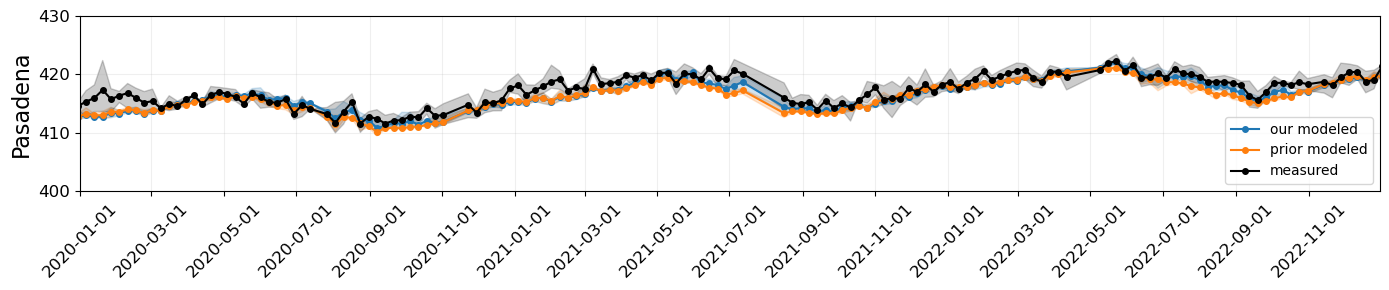

co2_wkt_tower-insitu_1_allvalid-457magl.nc


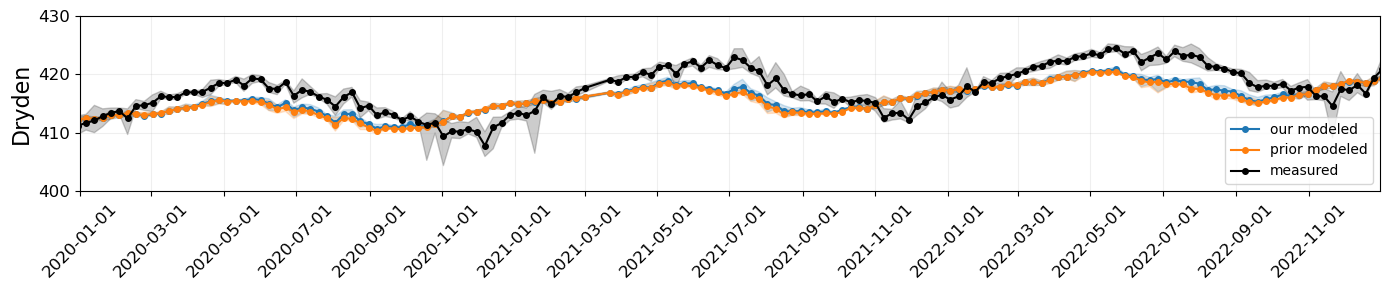

co2_wkt_tower-insitu_1_allvalid-457magl.nc


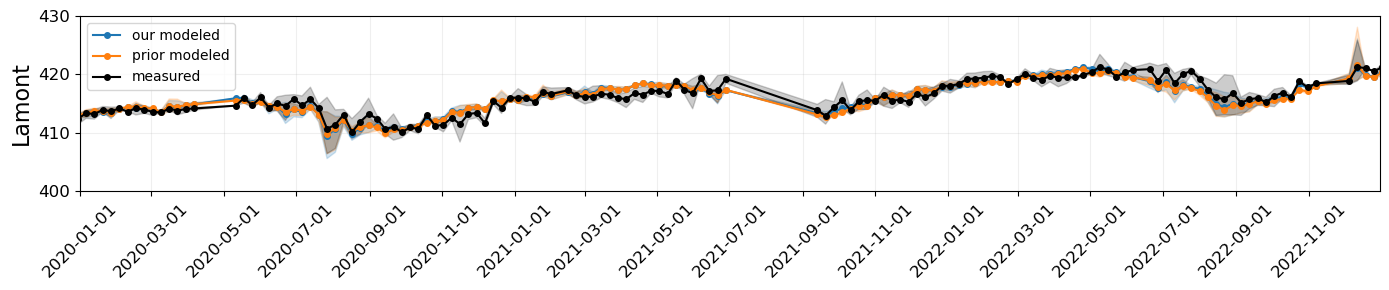

co2_wkt_tower-insitu_1_allvalid-457magl.nc


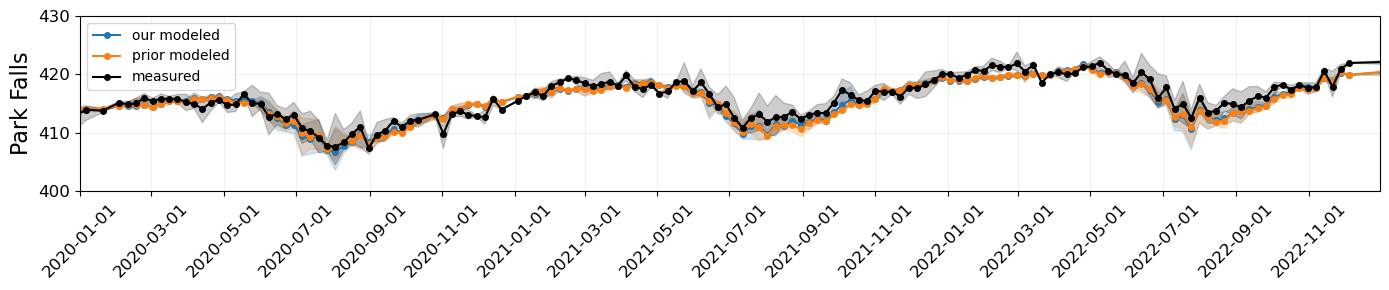

In [38]:
i=0
for site in tccon_sites:
    fig,axs=plt.subplots(1,1,figsize=(14,3))
    #fig.suptitle(f'Measured/Modeled In-Situ, {station[4:7]}',fontsize=14)
    default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    temp=inversion.tccon.where(( inversion.tccon.site_id==site),drop=True)
    temp['diurnal']=temp.real_xco2-temp.xco2
    temp['xco2_modeled_posterior']=temp.posterior_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
    temp['xco2_modeled_prior']=temp.prior_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
    temp['xco2_modeled_TM5']=temp.ref_RemoteC_IS_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
    weekly=temp.assign_coords(release_week=temp.release_week, release_box_lat=temp.release_box_lat, release_box_lon=temp.release_box_lon)
    if len(temp.pointspec)!=0:
        temp_mean=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).mean()
        temp_max=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).max()
        temp_min=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).min()
        # our posterior
        axs.plot(temp_mean.release_week, (temp_mean.xco2_modeled_posterior).mean([ 'release_box_lat', 'release_box_lon']), marker='o', color=default_colors[0], markersize=4,label='our modeled')
        axs.fill_between(temp_mean.release_week, temp_min.xco2_modeled_posterior.min([ 'release_box_lat', 'release_box_lon']),temp_max.xco2_modeled_posterior.max([ 'release_box_lat', 'release_box_lon']), color=default_colors[0], alpha=0.2) 
        axs.plot(temp_mean.release_week, temp_mean.xco2_modeled_prior.mean([ 'release_box_lat', 'release_box_lon']), marker='o', color=default_colors[1], markersize=4,label='prior modeled')
        axs.fill_between(temp_mean.release_week, temp_min.xco2_modeled_prior.min([ 'release_box_lat', 'release_box_lon']),temp_max.xco2_modeled_prior.max([ 'release_box_lat', 'release_box_lon']), color=default_colors[1], alpha=0.2) 
        axs.plot(temp_mean.release_week, temp_mean.real_xco2.mean([ 'release_box_lat', 'release_box_lon']), marker='o', color='black', markersize=4,label='measured')
        axs.fill_between(temp_mean.release_week, temp_min.real_xco2.min([ 'release_box_lat', 'release_box_lon']),temp_max.real_xco2.max([ 'release_box_lat', 'release_box_lon']), color='black', alpha=0.2) 
        # TM5-4DVar
        #axs.plot(temp_mean.release_week, temp_mean.co2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color='grey', markersize=4,label='TM5-4DVar modeled', alpha=0.5)
        #axs.fill_between(temp_min.release_week, temp_min.co2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.co2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']), color='grey', alpha=0.1) 
        axs.legend()
    print(station)
    label=temp.name.values[0]
    axs.set_ylabel(label,fontsize=16)
    axs.set_ylim(400,430)
    axs.grid(visible=True, which='major', axis='both', alpha=0.2)
    axs.set_xticks(pd.date_range(analysis_start_date,analysis_end_date,freq='2MS'))
    axs.tick_params(axis='x', labelrotation=45, labelsize=12)
    axs.tick_params(axis='y', labelsize=12)
    axs.set_xlim(analysis_start_date,analysis_end_date)
    plt.tight_layout()
    plt.savefig(f'{savefig_TCCON}/stations/measurement_timeline_TCCON_modeled_measured_{site}.pdf',bbox_inches='tight')#,transparent=True)
    #plt.show()
    plt.show()


In [65]:
text=""
for site in tccon_sites:
    text+=f"{site}\t"
print(text)

ci	df	oc	pa	


In [37]:
savefig_TCCON

'figures_2/3years/model_anaylsis/measurements/TCCON/'

In [75]:
temp=inversion.tccon.where(inversion.tccon.name=='Dryden',drop=True)
print(str(temp.release_lat.values[0])+'N, '+str(-temp.release_lon.values[1])+'W')
temp=inversion.tccon.where(inversion.tccon.name=='Pasadena',drop=True)
print(str(temp.release_lat.values[0])+'N, '+str(-temp.release_lon.values[1])+'W')


34.95999N, 117.87999W
34.140003N, 118.12999W


In [17]:
fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(40,20))
#fig.suptitle('Measured/Modeled GOSAT',fontsize=14)
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
for i in range(2): #lat(0.02, plt.cm.Reds(0.60)),
    for j in range(3): #lon
        temp=inversion.gosat.where(((inversion.gosat.release_box_lat>= regions_lat[-i-2]) &(inversion.gosat.release_box_lat<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.release_box_lon>= regions_lon[j]) &(temp.release_box_lon<regions_lon[j+1])),drop=True)
        temp['diurnal']=temp.real_xco2-temp.xco2
        temp['xco2_modeled_posterior']=temp.posterior_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
        temp['xco2_modeled_prior']=temp.prior_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
        temp['xco2_modeled_TM5']=temp.ref_RemoteC_IS_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
        weekly=temp.assign_coords(release_week=temp.release_week, release_box_lat=temp.release_box_lat, release_box_lon=temp.release_box_lon)
        if len(temp.pointspec)!=0:
            temp_mean=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).mean()
            temp_max=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).max()
            temp_min=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).min()
            axs[i,j].plot(temp_mean.release_week, (temp_mean.xco2_modeled_posterior).mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[0], markersize=4,label='our modeled')
            axs[i,j].fill_between(temp_min.release_week, temp_min.xco2_modeled_posterior.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.xco2_modeled_posterior.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[0], alpha=0.2) 
            axs[i,j].plot(temp_mean.release_week, temp_mean.xco2_modeled_prior.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[1], markersize=4,label='prior modeled')
            axs[i,j].fill_between(temp_min.release_week, temp_min.xco2_modeled_prior.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.xco2_modeled_prior.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[1], alpha=0.2) 
            axs[i,j].plot(temp_mean.release_week, temp_mean.real_xco2.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color='black', markersize=4,label='measured')
            axs[i,j].fill_between(temp_min.release_week, temp_min.real_xco2.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.real_xco2.mean(dim=['release_box_lat', 'release_box_lon']), color='black', alpha=0.2) 
            #axs[i,j].plot(temp_mean.release_week, temp_mean.xco2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[3], markersize=4,label='TM5-4DVar modeled')
            #axs[i,j].fill_between(temp_min.release_week, temp_min.xco2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.xco2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[3], alpha=0.2) 
            axs[i,j].legend()
            
        axs[i,j].set_ylabel('')
        axs[i,j].set_ylim(400,430)
        
        axs[i,j].grid(visible=True, which='major', axis='both', alpha=0.2)
        axs[i,j].set_xticks(pd.date_range(analysis_start_date,analysis_end_date,freq='2MS'))
        axs[i,j].tick_params(axis='x', labelrotation=45)
        axs[i,j].set_xlim(analysis_start_date,analysis_end_date)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")

plt.tight_layout()
plt.show()
#plt.close()

In [ ]:
fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(40,20))
#fig.suptitle('Measured/Modeled GOSAT',fontsize=14)
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
for i in range(2): #lat(0.02, plt.cm.Reds(0.60)),
    for j in range(2): #lon
        temp=inversion.gosat.where(((inversion.gosat.release_box_lat>= regions_lat[-i-2]) &(inversion.gosat.release_box_lat<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.release_box_lon>= regions_lon[j]) &(temp.release_box_lon<regions_lon[j+1])),drop=True)
        temp['diurnal']=temp.real_xco2-temp.xco2
        temp['xco2_modeled_posterior']=temp.posterior_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
        temp['xco2_modeled_prior']=temp.prior_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
        temp['xco2_modeled_TM5']=temp.ref_RemoteC_IS_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
        weekly=temp.assign_coords(release_week=temp.release_week, release_box_lat=temp.release_box_lat, release_box_lon=temp.release_box_lon)
        if len(temp.pointspec)!=0:
            temp_mean=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).mean()
            temp_max=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).max()
            temp_min=weekly.groupby(['release_week', 'release_box_lat', 'release_box_lon']).min()
            axs[i,j].plot(temp_mean.release_week, (temp_mean.xco2_modeled_posterior).mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[0], markersize=4,label='our modeled')
            axs[i,j].fill_between(temp_min.release_week, temp_min.xco2_modeled_posterior.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.xco2_modeled_posterior.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[0], alpha=0.2) 
            axs[i,j].plot(temp_mean.release_week, temp_mean.xco2_modeled_prior.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[1], markersize=4,label='prior modeled')
            axs[i,j].fill_between(temp_min.release_week, temp_min.xco2_modeled_prior.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.xco2_modeled_prior.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[1], alpha=0.2) 
            axs[i,j].plot(temp_mean.release_week, temp_mean.real_xco2.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color='black', markersize=4,label='measured')
            axs[i,j].fill_between(temp_min.release_week, temp_min.real_xco2.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.real_xco2.mean(dim=['release_box_lat', 'release_box_lon']), color='black', alpha=0.2) 
            #axs[i,j].plot(temp_mean.release_week, temp_mean.xco2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color=default_colors[3], markersize=4,label='TM5-4DVar modeled')
            #axs[i,j].fill_between(temp_min.release_week, temp_min.xco2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.xco2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']), color=default_colors[3], alpha=0.2) 
            axs[i,j].legend()
            
        axs[i,j].set_ylabel('')
        axs[i,j].set_ylim(400,430)
        
        axs[i,j].grid(visible=True, which='major', axis='both', alpha=0.2)
        axs[i,j].set_xticks(pd.date_range(analysis_start_date,analysis_end_date,freq='2MS'))
        axs[i,j].tick_params(axis='x', labelrotation=45)
        axs[i,j].set_xlim(analysis_start_date,analysis_end_date)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")

plt.tight_layout()
plt.show()
#plt.close()

In [15]:
inversion.gosat

<xarray.Dataset> Size: 8MB
Dimensions:                                                (pointspec: 20067)
Coordinates:
  * pointspec                                              (pointspec) int64 161kB ...
    height                                                 float32 4B 30.0
Data variables: (12/48)
    release_num                                            (pointspec) float64 161kB ...
    release_day                                            (pointspec) datetime64[ns] 161kB ...
    release_time                                           (pointspec) datetime64[ns] 161kB ...
    release_lat                                            (pointspec) float64 161kB ...
    release_lon                                            (pointspec) float64 161kB ...
    xco2                                                   (pointspec) float64 161kB ...
    ...                                                     ...
    ref_COLA_diff                                          (pointspec) float64 161kB ...
    ref_GCASv2_diff                                        (pointspec) float64 161kB ...
    ref_UoE_diff                                           (pointspec) float64 161kB ...
    ref_IAPCAS_diff                                        (pointspec) float64 161kB ...
    ref_MIROC_diff                                         (pointspec) float64 161kB ...
    ref_NTFVAR_diff                                        (pointspec) float64 161kB ...
Attributes: (12/37)
    Conventions:            CF-1.6
    title:                  FLEXPART model output
    git:                    ffadcb5 Fri Sep 19 15:51:15 2025 +0000
    source:                 Version 11.0 (2023-07-11) model output
    history:                2026-06-20 14:56 +0200  created by b383736 on l40...
    references:             Stohl et al., Atmos. Chem. Phys., 2005, doi:10.51...
    ...                     ...
    ind_source:             1
    ind_receptor:           2
    mquasilag:              0
    nested_output:          0
    sfc_only:               0
    linit_cond:             0

In [18]:
np.max(inversion.fluxes.meas_cov)

<xarray.DataArray 'meas_cov' ()> Size: 8B
array(10.77032961)
Coordinates:
    height   float32 4B 30.0

(array([2.3280e+03, 1.6358e+04, 4.3440e+03, 4.1580e+03, 5.2780e+03,
        3.4900e+03, 1.5140e+03, 6.5000e+02, 1.3900e+02, 1.1000e+01]),
 array([ 2.        ,  2.87703296,  3.75406592,  4.63109888,  5.50813185,
         6.38516481,  7.26219777,  8.13923073,  9.01626369,  9.89329665,
        10.77032961]),
 <BarContainer object of 10 artists>)

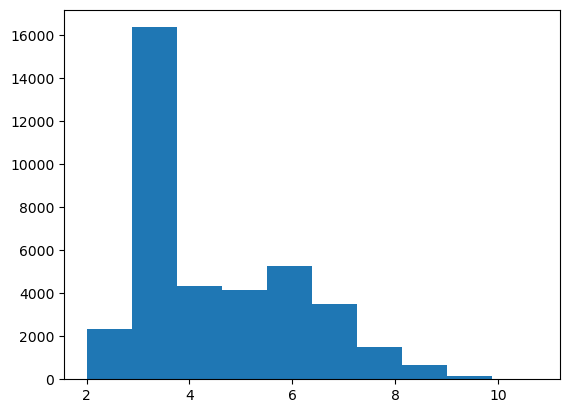

In [23]:
plt.hist(inversion.fluxes.meas_cov.mean('time').values)